# Auditoría de datos — Pipeline UNISON

Esta libreta **solo lee** los artefactos del proyecto. No descarga, no sobrescribe Parquet y no
modifica el pipeline. Su objetivo es revisar el linaje completo de los datos, etapa por etapa,
y dejar un diagnóstico explícito.

**Orden de revisión**

1. Descarga cruda (`data/raw/`).
2. Corpus analizable (`data/interim/corpus_analisis.parquet`).
3. Cuerpos completos (`data/interim/cuerpos_full.parquet`).
4. Menciones extraídas (`data/interim/noticias_limpias_full.parquet`).
5. Cobertura, brecha y olvido (`data/processed/`).
6. Tópicos (`data/processed/topicos_*.parquet`).
7. Narrativa y figuras (`reports/`).
8. Diagnóstico final.

Cada sección imprime estructura, aplica invariantes y deja una observación. Los `assert`
fallan si el dato deja de cumplir lo que el pipeline promete; las anomalías conocidas se
reportan como **observaciones**, no como fallos.


In [1]:
from pathlib import Path
from IPython.display import Image, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

CWD = Path.cwd()
RAIZ = next(
    p for p in [CWD, CWD.parent, CWD.parent.parent]
    if (p / "data").exists() and (p / "src").exists()
)
print("Raíz del proyecto:", RAIZ)

ESPERADO = {
    "raw_full": 37_975,
    "raw_full_enlaces_unicos": 37_975,
    "raw_full_notas_internas": 37_882,
    "corpus": 37_882,
    "cuerpos": 37_882,
    "menciones": 22_403,
    "notas_con_mencion": 15_386,
    "programas_catalogo": 131,
    "programas_activos": 129,
    "pregrado_menciones": 17_763,
    "posgrado_menciones": 4_640,
    "olvido": 34,
    "topicos": 15,
    "topicos_programas": 1_935,
    "topicos_nivel": 30,
    "categorias": 20,
}

PATRON_NOTA = r"^https?://(?:www\.)?unison\.mx/nota/\?idnoti=\d+"
hallazgos = []


def registrar(etapa: str, estado: str, detalle: str) -> None:
    """Registra un resultado de auditoría para el diagnóstico final."""
    hallazgos.append({"Etapa": etapa, "Estado": estado, "Detalle": detalle})


def perfil(df: pd.DataFrame, nombre: str) -> None:
    """Imprime forma, columnas, tipos, nulos y únicos de un DataFrame."""
    print(f"{nombre}: {len(df):,} filas × {df.shape[1]} columnas")
    tabla = pd.DataFrame(
        {
            "Columna": df.columns,
            "Tipo": [str(t) for t in df.dtypes],
            "No nulos": df.notna().sum().to_numpy(),
            "Nulos": df.isna().sum().to_numpy(),
            "Únicos": [df[c].nunique(dropna=True) for c in df.columns],
        }
    )
    display(tabla)


print("Valores esperados cargados:", len(ESPERADO))


Raíz del proyecto: D:\loba\Documents\Github\Proyectos Tareas MCD\PLN_historia_unison
Valores esperados cargados: 16


## 1. Descarga cruda

**Qué se revisa:** que el archivo completo sea la fuente maestra, que los enlaces sean
consistentes y que la muestra histórica no se confunda con el corpus final.

**Archivos:** `data/raw/noticias_raw_full.parquet`, `noticias_raw.parquet`,
`noticias_relevantes.parquet`.


In [2]:
raw_full = pd.read_parquet(RAIZ / "data/raw/noticias_raw_full.parquet")
raw_sample = pd.read_parquet(RAIZ / "data/raw/noticias_raw.parquet")
relevantes = pd.read_parquet(RAIZ / "data/raw/noticias_relevantes.parquet")

perfil(raw_full, "noticias_raw_full")
display(raw_full.head(5))

assert len(raw_full) == ESPERADO["raw_full"], "Cambió el número de filas del crudo"
assert raw_full["Fecha_ISO"].notna().all(), "Hay fechas nulas en el crudo"
assert raw_full["Enlace"].notna().all(), "Hay enlaces nulos en el crudo"
assert raw_full["Año"].nunique() == 24, "Se esperaban 24 años (2003–2026)"

raw_full["Es_Nota"] = raw_full["Enlace"].str.match(PATRON_NOTA)
print("\nNotas internas vs enlaces externos/no-nota:")
print(raw_full["Es_Nota"].value_counts().to_string())
assert raw_full.loc[raw_full["Es_Nota"], "Enlace"].nunique() == ESPERADO["raw_full_notas_internas"]

duplicados = raw_full[raw_full["Enlace"].duplicated(keep=False)].sort_values("Enlace")
print(
    f"\nEnlaces duplicados en el crudo: {len(duplicados)} filas en grupos duplicados "
    f"({raw_full['Enlace'].duplicated().sum()} duplicados extra)"
)
display(duplicados[["Fecha_ISO", "Título", "Enlace"]].head(10))

meses = set(raw_full["Fecha_ISO"].str[:7])
esperados_meses = {f"{a}-{m:02d}" for a in range(2003, 2027) for m in range(1, 13)}
faltantes = sorted(esperados_meses - meses)
print(f"\nMeses presentes: {len(meses)} de {len(esperados_meses)}")
print("Meses ausentes:", faltantes)
assert len(meses) == 286
assert faltantes == ["2026-11", "2026-12"]

print(f"\nMuestra histórica: {len(raw_sample):,} filas, "
      f"{raw_sample['Enlace'].nunique():,} enlaces únicos")
fuera = raw_sample[~raw_sample["Enlace"].isin(set(raw_full["Enlace"]))]
print("Filas de la muestra que no están en el crudo completo:", len(fuera))
display(fuera[["Fecha_ISO", "Título", "Enlace"]])
assert len(fuera) <= 1

print(f"\nNoticias relevantes (piloto): {len(relevantes):,} filas")
print("Tiene_Programa:", relevantes["Tiene_Programa"].value_counts().to_dict())
print("Tiene_Admision:", relevantes["Tiene_Admision"].value_counts().to_dict())
assert relevantes["Enlace"].isin(set(raw_full["Enlace"])).all()

registrar(
    "1. Crudo",
    "OK con observaciones",
    f"{len(raw_full):,} filas; {raw_full['Enlace'].nunique():,} enlaces únicos; "
    f"{raw_full['Enlace'].duplicated().sum()} enlaces duplicados extra; 286/288 meses; "
    f"muestra con {len(fuera)} enlace fuera del crudo.",
)


noticias_raw_full: 37,975 filas × 5 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Título,str,37975,0,37696
1,Fecha Original,str,37975,0,6598
2,Fecha_ISO,str,37975,0,6598
3,Enlace,str,37975,0,37975
4,Año,int64,37975,0,24


,Título,Fecha Original,Fecha_ISO,Enlace,Año
0,Estudia Difus aplicaciones de diamante sintético,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=96,2003
1,Estudian procesamiento de vísceras de calamar ...,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=97,2003
2,Inicia segunda etapa del proceso de reinscripc...,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=98,2003
3,Distingue a académico de la Unison la UAM,7 de enero de 2003,2003-01-07,https://www.unison.mx/nota/?idnoti=99,2003
4,Entregan fichas para examen de colocación en I...,8 de enero de 2003,2003-01-08,https://www.unison.mx/nota/?idnoti=101,2003



Notas internas vs enlaces externos/no-nota:
Es_Nota
True     37882
False       93



Enlaces duplicados en el crudo: 0 filas en grupos duplicados (0 duplicados extra)


,Fecha_ISO,Título,Enlace



Meses presentes: 286 de 288
Meses ausentes: ['2026-11', '2026-12']



Muestra histórica: 2,841 filas, 2,836 enlaces únicos


Filas de la muestra que no están en el crudo completo: 1


,Fecha_ISO,Título,Enlace
1912,2019-02-28,28 de febrero de 2019,","



Noticias relevantes (piloto): 1,952 filas
Tiene_Programa: {True: 1295, False: 657}
Tiene_Admision: {False: 1269, True: 683}


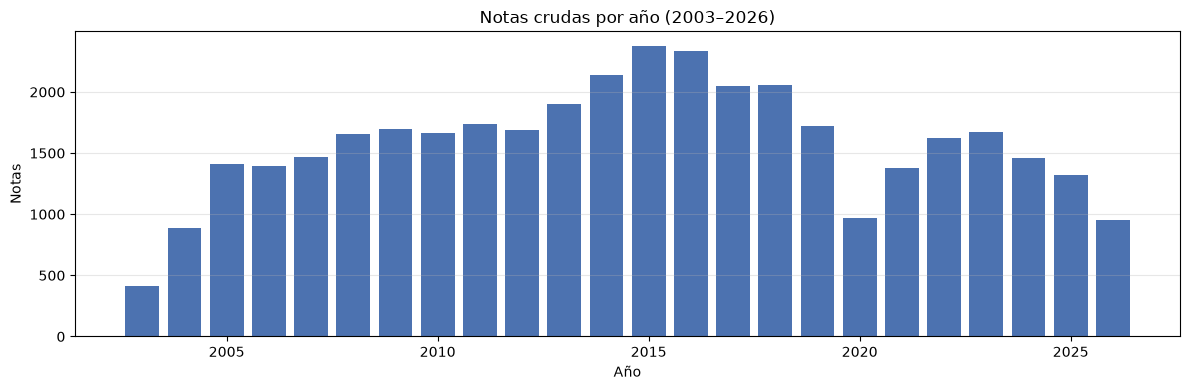

Notas por año:


Año,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Notas,411,886,1411,1398,1467,1657,1701,1666,1737,1685,1899,2138,2377,2337,2052,2059,1720,969,1377,1622,1671,1463,1317,955


In [3]:
por_anio = raw_full.groupby("Año").size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_anio.index, por_anio.values, color="#4c72b0")
ax.set_title("Notas crudas por año (2003–2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Notas")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

print("Notas por año:")
display(por_anio.to_frame("Notas").T)


## 2. Corpus analizable

**Qué se revisa:** que el corpus sea exactamente el subconjunto de notas internas del crudo,
sin duplicados y con la ventana temporal declarada.

**Archivo:** `data/interim/corpus_analisis.parquet`.


In [4]:
corpus = pd.read_parquet(RAIZ / "data/interim/corpus_analisis.parquet")
perfil(corpus, "corpus_analisis")
display(corpus.head(5))

assert len(corpus) == ESPERADO["corpus"]
assert corpus["Enlace"].is_unique, "El corpus tiene enlaces duplicados"
assert corpus["Enlace"].str.match(PATRON_NOTA).all(), "Hay enlaces que no son notas internas"
assert corpus["Fecha_ISO"].notna().all()
assert corpus["Año"].between(2003, 2026).all()

internas = raw_full.loc[raw_full["Es_Nota"], "Enlace"]
assert set(corpus["Enlace"]) == set(internas), "El corpus no coincide con las notas internas del crudo"

invalidos = corpus.loc[~corpus["Titulo_Valido"], ["Fecha_ISO", "Título", "Enlace"]]
print(f"\nTítulos inválidos conservados por el cuerpo: {len(invalidos)}")
display(invalidos.head(12))
assert len(invalidos) == 12

print(f"\nDiferencia crudo → corpus: {len(raw_full) - len(corpus)} filas")
print("Años del corpus:", corpus["Año"].min(), "→", corpus["Año"].max())
print("Notas por año:")
display(corpus.groupby("Año").size().to_frame("Notas").T)

registrar(
    "2. Corpus",
    "OK con observación",
    f"{len(corpus):,} notas internas; {len(raw_full) - len(corpus)} filas descartadas; "
    f"12 títulos inválidos conservados por cuerpo.",
)


corpus_analisis: 37,882 filas × 6 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Título,str,37882,0,37677
1,Fecha Original,str,37882,0,6594
2,Fecha_ISO,str,37882,0,6594
3,Enlace,str,37882,0,37882
4,Año,int64,37882,0,24
5,Titulo_Valido,bool,37882,0,2


,Título,Fecha Original,Fecha_ISO,Enlace,Año,Titulo_Valido
0,Estudia Difus aplicaciones de diamante sintético,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=96,2003,True
1,Estudian procesamiento de vísceras de calamar ...,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=97,2003,True
2,Inicia segunda etapa del proceso de reinscripc...,6 de enero de 2003,2003-01-06,https://www.unison.mx/nota/?idnoti=98,2003,True
3,Distingue a académico de la Unison la UAM,7 de enero de 2003,2003-01-07,https://www.unison.mx/nota/?idnoti=99,2003,True
4,Entregan fichas para examen de colocación en I...,8 de enero de 2003,2003-01-08,https://www.unison.mx/nota/?idnoti=101,2003,True



Títulos inválidos conservados por el cuerpo: 12


,Fecha_ISO,Título,Enlace
26589,2018-11-09,,https://www.unison.mx/nota/?idnoti=27256
28178,2019-10-25,.,https://www.unison.mx/nota/?idnoti=28978
28794,2020-02-21,.,https://www.unison.mx/nota/?idnoti=29627
29719,2021-03-08,.,https://www.unison.mx/nota/?idnoti=30671
29875,2021-04-19,.,https://www.unison.mx/nota/?idnoti=30838
29948,2021-05-09,.,https://www.unison.mx/nota/?idnoti=30911
29949,2021-05-10,.,https://www.unison.mx/nota/?idnoti=30912
29960,2021-05-13,.,https://www.unison.mx/nota/?idnoti=30926
29961,2021-05-14,.,https://www.unison.mx/nota/?idnoti=30931
30171,2021-07-26,.,https://www.unison.mx/nota/?idnoti=31143



Diferencia crudo → corpus: 93 filas
Años del corpus: 2003 → 2026
Notas por año:


Año,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Notas,411,886,1411,1398,1467,1657,1701,1666,1737,1685,1899,2138,2377,2337,2052,2059,1702,947,1362,1613,1652,1457,1313,955


## 3. Cuerpos completos

**Qué se revisa:** cobertura de descarga, correspondencia 1:1 con el corpus, longitud del
texto y calidad de la extracción del `div.entry-content`.

**Archivos:** `data/interim/cuerpos_full.parquet`, `cuerpos_noticias.parquet` (piloto).


In [5]:
cuerpos = pd.read_parquet(
    RAIZ / "data/interim/cuerpos_full.parquet",
    columns=["Enlace", "http_status", "ok", "chars", "cuerpo", "error", "intentos"],
)
perfil(cuerpos, "cuerpos_full")
display(cuerpos.head(3))

assert len(cuerpos) == ESPERADO["cuerpos"]
assert cuerpos["Enlace"].is_unique
assert set(cuerpos["Enlace"]) == set(corpus["Enlace"]), "Cuerpos y corpus no coinciden"
assert cuerpos["ok"].all(), "Hay descargas fallidas"
assert (cuerpos["http_status"] == 200).all(), "Hay códigos HTTP distintos de 200"
assert cuerpos["cuerpo"].str.len().gt(0).all(), "Hay cuerpos vacíos"
assert cuerpos["chars"].min() > 0

print("\nDistribución de longitud de los cuerpos:")
display(cuerpos["chars"].describe().to_frame().T.round(1))

cortos = cuerpos[cuerpos["chars"] <= 50].sort_values("chars")
print(f"\nCuerpos de 50 caracteres o menos: {len(cortos)}")
display(cortos[["Enlace", "chars", "cuerpo"]])
assert len(cortos) == 10

piloto = pd.read_parquet(
    RAIZ / "data/interim/cuerpos_noticias.parquet",
    columns=["Enlace", "ok", "chars", "cuerpo"],
)
print(f"\nPiloto de cuerpos: {len(piloto):,} filas")
print("Piloto contenido en el corpus completo:", piloto["Enlace"].isin(set(cuerpos["Enlace"])).all())
assert piloto["Enlace"].isin(set(cuerpos["Enlace"])).all()

registrar(
    "3. Cuerpos",
    "OK con observación",
    f"{len(cuerpos):,} cuerpos; 100% HTTP 200; "
    f"{len(cortos)} cuerpos ≤50 caracteres (fecha + punto).",
)


cuerpos_full: 37,882 filas × 7 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Enlace,str,37882,0,37882
1,http_status,float64,37882,0,1
2,ok,bool,37882,0,1
3,chars,int64,37882,0,5357
4,cuerpo,str,37882,0,37869
5,error,str,37882,0,1
6,intentos,int64,37882,0,2


,Enlace,http_status,ok,chars,cuerpo,error,intentos
0,https://www.unison.mx/nota/?idnoti=96,200.0,True,1652,06 de enero de 2003 A fin de medir la cantidad...,,1
1,https://www.unison.mx/nota/?idnoti=99,200.0,True,2499,07 de enero de 2003 Otorgó la Universidad Autó...,,1
2,https://www.unison.mx/nota/?idnoti=97,200.0,True,1799,06 de enero de 2003 Para aprovechar el 20 por ...,,1



Distribución de longitud de los cuerpos:


,count,mean,std,min,25%,50%,75%,max
chars,37882.0,2517.0,1237.4,20.0,1706.0,2245.0,3008.8,24180.0



Cuerpos de 50 caracteres o menos: 10


,Enlace,chars,cuerpo
30349,https://www.unison.mx/nota/?idnoti=30931,20,14 de mayo de 2021 .
30348,https://www.unison.mx/nota/?idnoti=30926,20,13 de mayo de 2021 -
30338,https://www.unison.mx/nota/?idnoti=30912,20,10 de mayo de 2021 .
30337,https://www.unison.mx/nota/?idnoti=30911,20,09 de mayo de 2021 .
30122,https://www.unison.mx/nota/?idnoti=30671,21,08 de marzo de 2021 .
30270,https://www.unison.mx/nota/?idnoti=30838,21,19 de abril de 2021 .
33228,https://www.unison.mx/nota/?idnoti=34036,21,12 de abril de 2023 .
33132,https://www.unison.mx/nota/?idnoti=33935,21,22 de marzo de 2023 .
29278,https://www.unison.mx/nota/?idnoti=29627,23,21 de febrero de 2020 .
2200,https://www.unison.mx/nota/?idnoti=350,24,08 de septiembre de 2003



Piloto de cuerpos: 1,952 filas


Piloto contenido en el corpus completo: True


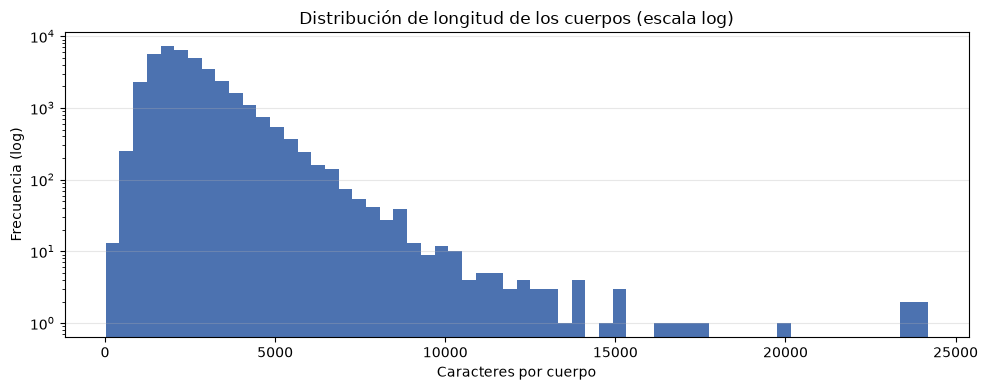

Muestra aleatoria para revisión manual (abre el enlace y compara):


,Enlace,chars,Extracto
23733,https://www.unison.mx/nota/?idnoti=23498,2787,17 de febrero de 2017 Con la finalidad de fort...
25512,https://www.unison.mx/nota/?idnoti=25467,3063,12 de enero de 2018 En la tarea de combate a l...
34928,https://www.unison.mx/nota/?idnoti=35845,3367,07 de junio de 2024 Elías Quijada Para consoli...
16381,https://www.unison.mx/nota/?idnoti=15463,1875,11 de septiembre de 2013 Dio inicio la IV temp...
1109,https://www.unison.mx/nota/?idnoti=21708,1931,10 de mayo de 2016 La Universidad de Sonora ha...
32693,https://www.unison.mx/nota/?idnoti=33436,2976,01 de diciembre de 2022 Elías Quijada La edad ...
5133,https://www.unison.mx/nota/?idnoti=3416,2120,22 de mayo de 2006 Dirigido a 60 profesores e ...
29468,https://www.unison.mx/nota/?idnoti=29857,1742,02 de junio de 2020 Redacción Con el 98% de la...
27087,https://www.unison.mx/nota/?idnoti=27171,2207,29 de octubre de 2018 Denisse López Martínez C...
21950,https://www.unison.mx/nota/?idnoti=21531,1601,15 de abril de 2016 Los problemas en los barri...


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cuerpos["chars"], bins=60, color="#4c72b0", log=True)
ax.set_title("Distribución de longitud de los cuerpos (escala log)")
ax.set_xlabel("Caracteres por cuerpo")
ax.set_ylabel("Frecuencia (log)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

muestra_cuerpos = cuerpos.sample(10, random_state=20261103).copy()
muestra_cuerpos["Extracto"] = muestra_cuerpos["cuerpo"].str.slice(0, 220)
print("Muestra aleatoria para revisión manual (abre el enlace y compara):")
display(muestra_cuerpos[["Enlace", "chars", "Extracto"]])


## 4. Menciones extraídas

**Qué se revisa:** que cada mención tenga un programa válido, que no haya duplicados
`(Enlace, Programa)` y que los totales coincidan con los reportados en Fase 1.

**Archivos:** `data/interim/noticias_limpias_full.parquet` (principal) y
`noticias_limpias.parquet` (legado solo títulos).


In [7]:
menciones = pd.read_parquet(
    RAIZ / "data/interim/noticias_limpias_full.parquet",
    columns=[
        "Fecha_ISO", "Año", "Título", "Enlace", "Mencion",
        "Nivel", "Grupo", "Programa", "Fuente_Mencion",
    ],
)
perfil(menciones, "noticias_limpias_full")

assert len(menciones) == ESPERADO["menciones"]
assert menciones["Enlace"].nunique() == ESPERADO["notas_con_mencion"]
assert menciones["Programa"].nunique() == ESPERADO["programas_activos"]
assert not menciones.duplicated(["Enlace", "Programa"]).any(), "Hay menciones duplicadas"
assert set(menciones["Enlace"]).issubset(set(corpus["Enlace"])), "Hay enlaces fuera del corpus"
assert menciones["Programa"].notna().all()
assert menciones["Grupo"].isin(["Pregrado", "Posgrado"]).all()

print("\nMenciones por nivel:")
print(menciones["Grupo"].value_counts().to_string())
assert menciones.groupby("Grupo").size().to_dict() == {
    "Pregrado": ESPERADO["pregrado_menciones"],
    "Posgrado": ESPERADO["posgrado_menciones"],
}

print("\nFuente de la mención:")
print(menciones["Fuente_Mencion"].value_counts().to_string())
print("\nProgramas por nivel:")
print(menciones.groupby(["Grupo", "Nivel"]).size().to_string())

legado = pd.read_parquet(RAIZ / "data/interim/noticias_limpias.parquet")
print(f"\nLegado solo títulos: {len(legado):,} menciones, "
      f"{legado['Enlace'].nunique():,} notas, {legado['Programa'].nunique()} programas")
print("Es aditivo con la full-text: NO. Úsalo solo como referencia histórica.")

registrar(
    "4. Menciones",
    "OK",
    f"{len(menciones):,} menciones en {menciones['Enlace'].nunique():,} notas; "
    f"{menciones['Programa'].nunique()} programas; sin duplicados (Enlace, Programa).",
)


noticias_limpias_full: 22,403 filas × 9 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Fecha_ISO,str,22403,0,5430
1,Año,int64,22403,0,24
2,Título,str,22403,0,15332
3,Enlace,str,22403,0,15386
4,Mencion,str,22403,0,4203
5,Nivel,str,22403,0,4
6,Grupo,str,22403,0,2
7,Programa,str,22403,0,129
8,Fuente_Mencion,str,22403,0,3



Menciones por nivel:
Grupo
Pregrado    17763
Posgrado     4640

Fuente de la mención:
Fuente_Mencion
Cuerpo             20917
Título y cuerpo     1364
Título               122

Programas por nivel:
Grupo     Nivel       
Posgrado  Especialidad      203
          Posgrado         4437
Pregrado  Ingeniería       5027
          Licenciatura    12736

Legado solo títulos: 1,486 menciones, 1,403 notas, 126 programas
Es aditivo con la full-text: NO. Úsalo solo como referencia histórica.


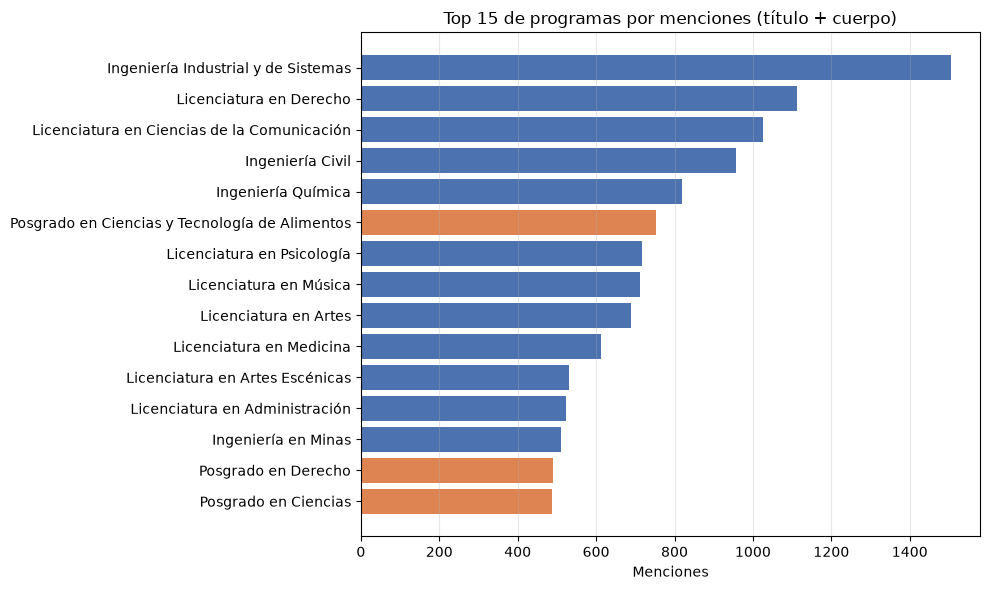

Muestra aleatoria de menciones para revisión semántica:


,Fecha_ISO,Título,Programa,Fuente_Mencion
17079,2022-02-11,Promueven convocatorias para posgrados en Cien...,Posgrado en Ciencias,Título y cuerpo
19706,2024-03-04,Con emotivo conversatorio celebran 60 años de ...,Posgrado en Literatura Hispanoamericana,Cuerpo
4096,2009-12-08,Inauguran Seminario de Investigación en Enferm...,Licenciatura en Enfermería,Cuerpo
1126,2005-11-15,Inicia hoy Foro Fiscal y de Contabilidad en URS,Licenciatura en Contaduría Pública,Cuerpo
18349,2023-02-07,División de Ingeniería de Unison ofrece posgra...,Posgrado en Ingeniería Urbana,Cuerpo
21105,2025-06-02,Estudiante de la UAS realiza estancia académic...,Posgrado en Ciencias,Cuerpo
3665,2009-08-17,Supera Unison expectativas de nuevo ingreso,Licenciatura en Medicina,Cuerpo
11812,2017-02-17,Necesario aplicar la tecnología 3D en el área ...,Licenciatura en Artes Plásticas,Cuerpo
17401,2022-05-10,Estudiar Medicina en el campus Navojoa es el s...,Licenciatura en Educación,Cuerpo
7847,2014-01-23,Abren inscripciones para el curso de zancos de...,Ingeniería Industrial y de Sistemas,Cuerpo


In [8]:
top_programas = (
    menciones.groupby(["Programa", "Grupo"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="Menciones")
)
fig, ax = plt.subplots(figsize=(10, 6))
colores = top_programas["Grupo"].map({"Pregrado": "#4c72b0", "Posgrado": "#dd8452"})
ax.barh(top_programas["Programa"][::-1], top_programas["Menciones"][::-1], color=colores[::-1])
ax.set_xlabel("Menciones")
ax.set_title("Top 15 de programas por menciones (título + cuerpo)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

muestra_menciones = menciones.sample(12, random_state=20261103)
print("Muestra aleatoria de menciones para revisión semántica:")
display(muestra_menciones[["Fecha_ISO", "Título", "Programa", "Fuente_Mencion"]])


## 5. Cobertura, brecha y olvido

**Qué se revisa:** que los agregados reconcilien con las menciones y que las métricas
derivadas (Top-k, HHI, Gini, cuartiles, tasas) se puedan recalcular.

**Archivos:** `cobertura_programas`, `brecha_nivel`, `cobertura_anual`, `evolucion_nivel`,
`olvido_mediatico`, `concentracion`, `resumen_pc2`.


In [9]:
cobertura = pd.read_parquet(RAIZ / "data/processed/cobertura_programas.parquet")
brecha = pd.read_parquet(RAIZ / "data/processed/brecha_nivel.parquet")
anual = pd.read_parquet(RAIZ / "data/processed/cobertura_anual.parquet")
evolucion = pd.read_parquet(RAIZ / "data/processed/evolucion_nivel.parquet")
olvido = pd.read_parquet(RAIZ / "data/processed/olvido_mediatico.parquet")
concentracion = pd.read_parquet(RAIZ / "data/processed/concentracion.parquet")
resumen = pd.read_parquet(RAIZ / "data/processed/resumen_pc2.parquet")

perfil(cobertura, "cobertura_programas")
assert len(cobertura) == ESPERADO["programas_catalogo"]
assert int(cobertura["Menciones"].sum()) == ESPERADO["menciones"]
assert int((cobertura["Notas"] == cobertura["Menciones"]).sum()) == len(cobertura)
assert int((cobertura["Notas"] == 0).sum()) == 2

perfil(brecha, "brecha_nivel")
assert len(brecha) == 2
assert int(brecha["Menciones"].sum()) == ESPERADO["menciones"]
assert int(brecha["Notas"].sum()) == 16_522
print("\nNotas por nivel suman 16,522, pero las notas únicas son 15,386.")
print("La diferencia son notas que mencionan programas de ambos niveles.")
print("No sumes las notas por nivel como si fueran notas únicas.")

perfil(anual, "cobertura_anual")
assert anual["Año"].nunique() == 24
assert int(anual["Notas"].sum()) == ESPERADO["menciones"]
print(f"Combinaciones programa-año presentes: {len(anual):,}")
print(f"Cuadrícula completa 131×24: {ESPERADO['programas_catalogo'] * 24:,}")
print("Filas ausentes = combinaciones con cero menciones (no son errores).")

perfil(evolucion, "evolucion_nivel")
print("\nPeriodos por tipo:")
print(evolucion["Periodo_Tipo"].value_counts().to_string())
print("\nPeriodos marcados como parciales:")
display(
    evolucion.loc[evolucion["Es_Periodo_Parcial"], ["Periodo", "Grupo", "Periodo_Tipo"]]
    .drop_duplicates()
)

perfil(olvido, "olvido_mediatico")
print("\nCategorías de olvido:")
print(olvido.groupby(["Categoria_Olvido", "Grupo"]).size().to_string())
assert len(olvido) == ESPERADO["olvido"]
assert int((olvido["Grupo"] == "Posgrado").sum()) == 31
assert int((olvido["Categoria_Olvido"] == "Sin mención").sum()) == 2
assert olvido["Notas"].max() <= 18

perfil(concentracion, "concentracion")
s = cobertura.sort_values("Menciones", ascending=False)["Menciones"] / cobertura["Menciones"].sum()
top = {k: round(s.head(k).sum() * 100, 2) for k in [1, 5, 10, 20, 50]}
hhi = round((s**2).sum() * 10_000, 2)
x = np.sort(cobertura["Menciones"].to_numpy())
n = len(x)
gini = (2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())
print("\nRecálculo desde cobertura_programas:")
print(f"Top 1/5/10/20/50: {top}")
print(f"HHI: {hhi} | Gini: {gini:.3f}")
assert top[20] == 60.17
assert round(hhi, 1) == 244.9
assert round(gini, 3) == 0.661

perfil(resumen, "resumen_pc2")
sin_topic = resumen["Tópico Principal Asociado"].eq("Sin menciones (Fase 3)")
print(f"\nProgramas sin tópico asignado: {int(sin_topic.sum())}")
assert len(resumen) == ESPERADO["programas_catalogo"]
assert int(sin_topic.sum()) == 2

registrar(
    "5. Cobertura",
    "OK con observaciones",
    "Totales reconciliados; notas por nivel no son aditivas (16,522 vs 15,386); "
    "cobertura_anual omite ceros; 2026/2020s/2025-2029 son parciales.",
)


cobertura_programas: 131 filas × 16 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Programa,str,131,0,131
1,Nivel,str,131,0,4
2,Grupo,str,131,0,2
3,Notas,int64,131,0,97
4,Menciones,int64,131,0,97
5,Primer_Año,Int64,129,2,22
6,Ultimo_Año,Int64,129,2,12
7,Años_Activo,int64,131,0,24
8,Ranking,int64,131,0,97
9,% Cobertura institucional,float64,131,0,97


brecha_nivel: 2 filas × 14 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Grupo,str,2,0,2
1,Notas,int64,2,0,2
2,Menciones,int64,2,0,2
3,Programas,int64,2,0,2
4,Programas_Activos,int64,2,0,2
5,Menciones_por_Programa,int64,2,0,2
6,Promedio_Notas_Catalogo,float64,2,0,2
7,Mediana_Notas,float64,2,0,2
8,Maximo_Notas,int64,2,0,2
9,Promedio_Notas_Activos,float64,2,0,2



Notas por nivel suman 16,522, pero las notas únicas son 15,386.
La diferencia son notas que mencionan programas de ambos niveles.
No sumes las notas por nivel como si fueran notas únicas.
cobertura_anual: 1,935 filas × 9 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Año,int64,1935,0,24
1,Programa,str,1935,0,129
2,Nivel,str,1935,0,4
3,Grupo,str,1935,0,2
4,Notas,int64,1935,0,77
5,Notas_Periodo,int64,1935,0,24
6,% Cobertura anual,float64,1935,0,615
7,Notas por 1000,float64,1935,0,675
8,Es_Anio_Parcial,bool,1935,0,2


... (7 outputs left out)

,Columna,Tipo,No nulos,Nulos,Únicos
0,Metrica,str,9,0,9
1,Valor,float64,9,0,9



Recálculo desde cobertura_programas:
Top 1/5/10/20/50: {1: np.float64(6.71), 5: np.float64(24.18), 10: np.float64(39.72), 20: np.float64(60.17), 50: np.float64(87.88)}
HHI: 244.88 | Gini: 0.661
resumen_pc2: 131 filas × 25 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Ranking,int64,131,0,97
1,Programa,str,131,0,131
2,Nivel,str,131,0,4
3,Grupo,str,131,0,2
4,Total Menciones,int64,131,0,97
5,% Cobertura Institucional,float64,131,0,97
6,% del Subconjunto,float64,131,0,90
7,Categoria,str,131,0,5
8,Cuartil,str,131,0,4
9,Índice de Olvido,float64,131,0,87



Programas sin tópico asignado: 2


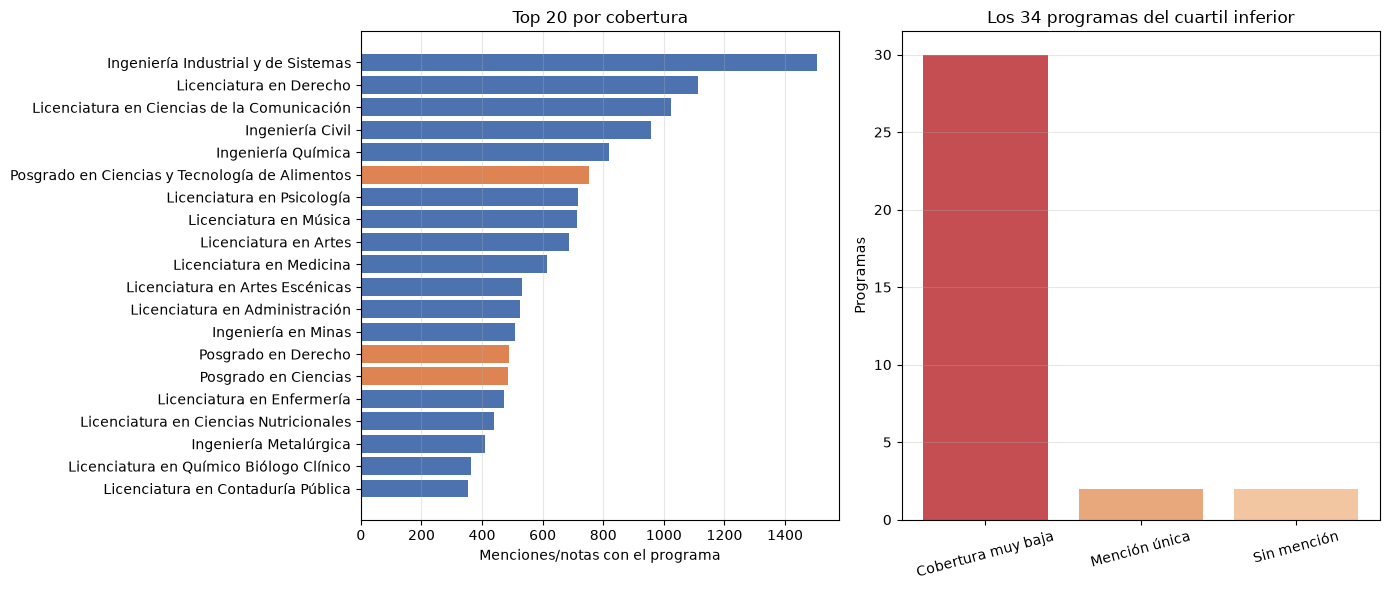

In [10]:
top20 = cobertura.head(20).sort_values("Notas")
fig, ejes = plt.subplots(1, 2, figsize=(14, 6))

colores = top20["Grupo"].map({"Pregrado": "#4c72b0", "Posgrado": "#dd8452"})
ejes[0].barh(top20["Programa"], top20["Notas"], color=colores)
ejes[0].set_title("Top 20 por cobertura")
ejes[0].set_xlabel("Menciones/notas con el programa")
ejes[0].grid(axis="x", alpha=0.3)

conteo = olvido.groupby("Categoria_Olvido").size()
ejes[1].bar(conteo.index, conteo.values, color=["#c44e52", "#e8a87c", "#f2c6a0"][: len(conteo)])
ejes[1].set_title(f"Los {len(olvido)} programas del cuartil inferior")
ejes[1].set_ylabel("Programas")
ejes[1].tick_params(axis="x", rotation=15)
ejes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()


## 6. Tópicos

**Qué se revisa:** que el modelo asignó 15 temas a los 129 programas activos, que los pesos
suman 100% por programa y 1.0 por nivel, y que la definición de temas es legible.

**Archivos:** `topicos_definicion.parquet`, `topicos_programas.parquet`,
`topicos_nivel.parquet`.


In [11]:
definicion = pd.read_parquet(RAIZ / "data/processed/topicos_definicion.parquet")
topicos = pd.read_parquet(RAIZ / "data/processed/topicos_programas.parquet")
nivel = pd.read_parquet(RAIZ / "data/processed/topicos_nivel.parquet")

perfil(definicion, "topicos_definicion")
display(definicion)

assert len(definicion) == ESPERADO["topicos"]
assert definicion["Tema"].is_unique

perfil(topicos, "topicos_programas")
assert len(topicos) == ESPERADO["topicos_programas"]
assert topicos["Programa"].nunique() == ESPERADO["programas_activos"]
assert topicos["Tema_Num"].nunique() == ESPERADO["topicos"]
assert topicos["Peso_Porcentaje"].notna().all()
assert not topicos.duplicated(["Programa", "Tema_Num"]).any()

suma_programa = topicos.groupby("Programa")["Peso_Porcentaje"].sum()
print("\nSuma de pesos por programa:")
print(suma_programa.describe().round(3).to_string())
assert suma_programa.between(99.9, 100.1).all()

perfil(nivel, "topicos_nivel")
assert len(nivel) == ESPERADO["topicos_nivel"]
suma_nivel = nivel.groupby("Grupo")["Peso_Medio"].sum()
print("\nSuma de pesos medios por nivel:")
print(suma_nivel.round(4).to_string())
assert suma_nivel.between(0.999, 1.001).all()

principal = topicos.loc[topicos.groupby("Programa")["Peso"].idxmax()]
print("\nTópicos principales asignados:")
display(
    principal.groupby(["Tema_Num", "Tema_Etiqueta"]).size().reset_index(name="Programas")
    .sort_values("Programas", ascending=False)
)

print("\nTop 10 de programas y su tópico principal:")
display(
    principal.sort_values("Notas", ascending=False)
    .head(10)[["Programa", "Grupo", "Notas", "Tema_Etiqueta", "Peso_Porcentaje"]]
)

assert set(topicos["Programa"]).issubset(set(resumen["Programa"]))

registrar(
    "6. Tópicos",
    "OK",
    f"15 temas; {len(topicos):,} filas ({ESPERADO['programas_activos']}×15); pesos por programa 99.97–100.03; "
    "pesos medios por nivel suman 1.0.",
)


topicos_definicion: 15 filas × 4 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Tema,int64,15,0,15
1,Etiqueta,str,15,0,15
2,Palabras,str,15,0,15
3,Coherencia_NPMI,float64,15,0,15


,Tema,Etiqueta,Palabras,Coherencia_NPMI
0,1,Sociedad y vida universitaria,ser / vida / cómo / rubio / sociedad / mujeres,0.0692
1,2,Premios y trayectorias,premio / trayectoria / estudiantil / rectora /...,0.2701
2,3,"Artes, música y danza",artes / música / danza / bellas / teatro / obra,0.3391
3,4,Salud y enfermería,salud / enfermería / medicina / módulos / aten...,0.2452
4,5,Admisión e ingreso,aspirantes / ingreso / examen / convocatoria /...,0.3934
5,6,Gobierno universitario,rector / ortega / romero / grijalva / montever...,0.3500
6,7,Alimentos y nutrición,alimentos / dipa / alimentación / radio / tiem...,0.3099
7,8,Calidad y evaluación educativa,acreditación / evaluación / calidad / consejo ...,0.2726
8,9,Eventos académicos,evento / conferencias / actividades / congreso...,0.1609
9,10,Egreso y graduación,ceremonia / egresados / generación / graduante...,0.3256


topicos_programas: 1,935 filas × 12 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Programa,str,1935,0,129
1,Nivel,str,1935,0,4
2,Grupo,str,1935,0,2
3,Tema,str,1935,0,15
4,Peso,float64,1935,0,1904
5,Tema_Num,int64,1935,0,15
6,Peso_Porcentaje,float64,1935,0,1087
7,Ranking,int64,1935,0,15
8,Es_Top3,bool,1935,0,2
9,Tema_Etiqueta,str,1935,0,15



Suma de pesos por programa:
count    129.000
mean      99.999
std        0.012
min       99.970
25%       99.990
50%      100.000
75%      100.010
max      100.030
topicos_nivel: 30 filas × 5 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Grupo,str,30,0,2
1,Tema,str,30,0,15
2,Peso_Medio,float64,30,0,30
3,Tema_Num,int64,30,0,15
4,Tema_Etiqueta,str,30,0,15



Suma de pesos medios por nivel:
Grupo
Posgrado    1.0
Pregrado    1.0

Tópicos principales asignados:


,Tema_Num,Tema_Etiqueta,Programas
12,13,Ingeniería y tecnología,26
13,14,Derecho y ciencias sociales,22
8,9,Eventos académicos,11
11,12,Vida estudiantil y movilidad,10
4,5,Admisión e ingreso,9
10,11,Divulgación científica,9
3,4,Salud y enfermería,7
6,7,Alimentos y nutrición,7
7,8,Calidad y evaluación educativa,5
9,10,Egreso y graduación,5



Top 10 de programas y su tópico principal:


,Programa,Grupo,Notas,Tema_Etiqueta,Peso_Porcentaje
180,Ingeniería Industrial y de Sistemas,Pregrado,1504,Ingeniería y tecnología,19.00
555,Licenciatura en Derecho,Pregrado,1112,Derecho y ciencias sociales,23.11
510,Licenciatura en Ciencias de la Comunicación,Pregrado,1025,Derecho y ciencias sociales,20.29
165,Ingeniería Civil,Pregrado,958,Ingeniería y tecnología,18.65
210,Ingeniería Química,Pregrado,818,Ingeniería y tecnología,25.68
1305,Posgrado en Ciencias y Tecnología de Alimentos,Posgrado,752,Alimentos y nutrición,49.70
900,Licenciatura en Psicología,Pregrado,716,Derecho y ciencias sociales,19.42
855,Licenciatura en Música,Pregrado,712,"Artes, música y danza",51.32
405,Licenciatura en Artes,Pregrado,688,"Artes, música y danza",57.25
810,Licenciatura en Medicina,Pregrado,613,Salud y enfermería,19.39


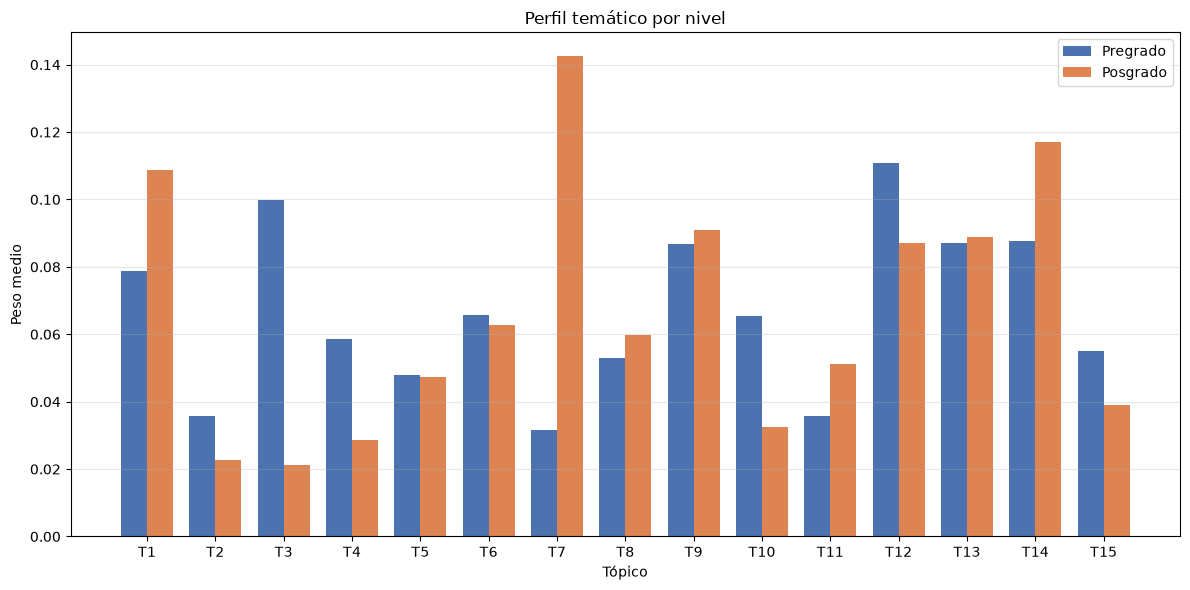

In [12]:
pivote = nivel.pivot(index="Tema_Num", columns="Grupo", values="Peso_Medio").fillna(0)
x = np.arange(len(pivote))
ancho = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
for i, grupo in enumerate(["Pregrado", "Posgrado"]):
    if grupo not in pivote.columns:
        continue
    ax.bar(
        x + (i - 0.5) * ancho,
        pivote[grupo],
        width=ancho,
        label=grupo,
        color=["#4c72b0", "#dd8452"][i],
    )
ax.set_xticks(x, [f"T{i}" for i in pivote.index])
ax.set_xlabel("Tópico")
ax.set_ylabel("Peso medio")
ax.set_title("Perfil temático por nivel")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


## 6b. Categorías B+

**Qué se revisa:** que la taxonomía fija cubra las notas, que `Otros` sea una sola categoría y que todos los programas tengan categoría principal.

In [13]:
cat_def = pd.read_parquet(RAIZ / 'data/processed/categorias_definicion.parquet')
cat_prog = pd.read_parquet(RAIZ / 'data/processed/categorias_programas.parquet')

perfil(cat_def, 'categorias_definicion')
display(cat_def[['Categoria', 'Notas', 'Porcentaje']])
assert len(cat_def) == ESPERADO['categorias']
assert int(cat_def['Notas'].sum()) == ESPERADO['notas_con_mencion']
assert int((cat_def['Categoria'] == 'Otros / no clasificable').sum()) == 1

perfil(cat_prog, 'categorias_programas')
assert cat_prog['Programa'].nunique() == ESPERADO['programas_activos']
assert cat_prog['Peso_Porcentaje'].between(0, 100).all()
assert cat_prog.groupby('Programa')['Es_Top3'].sum().between(1, 3).all()
assert 'Categoría Principal' in resumen.columns

print('Cobertura B+:', round((1 - cat_def.loc[cat_def['Categoria'] == 'Otros / no clasificable', 'Notas'].iloc[0] / len(menciones)) * 100, 2), '%')
registrar(
    '6b. Categorías B+',
    'OK',
    f"{len(cat_def)} categorías; {int(cat_def['Notas'].sum()):,} notas; "
    f"{int(cat_def.loc[cat_def['Categoria'] == 'Otros / no clasificable', 'Notas'].iloc[0]):,} en Otros.",
)


categorias_definicion: 20 filas × 4 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Categoria,str,20,0,20
1,Notas,int64,20,0,20
2,Porcentaje,float64,20,0,20
3,Descripcion,str,20,0,20


,Categoria,Notas,Porcentaje
0,Otros / no clasificable,1838,11.95
1,Artes y cultura,1836,11.93
2,Oferta educativa y docencia,1376,8.94
3,Eventos académicos y congresos,1286,8.36
4,Salud y medicina,1180,7.67
5,Investigación y ciencia,997,6.48
6,Sustentabilidad y medio ambiente,850,5.52
7,Vinculación y sector productivo,701,4.56
8,Egresados y graduación,592,3.85
9,Admisión e ingreso,569,3.70


categorias_programas: 1,686 filas × 9 columnas


,Columna,Tipo,No nulos,Nulos,Únicos
0,Programa,str,1686,0,129
1,Nivel,str,1686,0,4
2,Grupo,str,1686,0,2
3,Categoria,str,1686,0,20
4,Menciones,int64,1686,0,106
5,Notas,int64,1686,0,106
6,Peso_Porcentaje,float64,1686,0,684
7,Ranking,int64,1686,0,20
8,Es_Top3,bool,1686,0,2


Cobertura B+: 91.8 %


## 7. Narrativa y figuras

**Qué se revisa:** que el reporte exista, que las siete figuras estén presentes y que las
cifras clave del reporte coincidan con los artefactos.


In [14]:
reporte = RAIZ / "reports/fase4_narrativa.md"
figuras = sorted((RAIZ / "reports/figures").glob("fig0*.png"))

print("Reporte:", reporte.relative_to(RAIZ), "|", f"{reporte.stat().st_size:,} bytes")
texto = reporte.read_text(encoding="utf-8")

print("\nFiguras encontradas:")
for figura in figuras:
    print(f"  {figura.name}: {figura.stat().st_size:,} bytes")
assert len(figuras) == 7
assert all(f.stat().st_size > 10_000 for f in figuras)

for figura in figuras:
    assert figura.stem[:5] in texto, f"{figura.name} no se menciona en el reporte"

assert "60.17" in texto
assert "58.58" in texto
assert "34" in texto

print("\nCifras clave del reporte:")
print(f"  Top 20: {top[20]}% de las menciones")
print(f"  Olvido: {len(olvido)} programas; {int((olvido['Grupo'] == 'Posgrado').sum())} de Posgrado")
print(f"  Sin mención: {int((olvido['Categoria_Olvido'] == 'Sin mención').sum())}")
print(f"  Tópicos: {topicos['Tema_Num'].nunique()}")

registrar(
    "7. Narrativa",
    "OK",
    "Reporte y siete figuras presentes; las cifras clave coinciden con los Parquet.",
)


Reporte: reports\fase4_narrativa.md | 26,187 bytes

Figuras encontradas:
  fig01_top20_cobertura.png: 144,532 bytes
  fig02_brecha_nivel.png: 66,021 bytes
  fig03_evolucion_nivel.png: 112,119 bytes
  fig04_topicos_nivel.png: 111,594 bytes
  fig05_topicos_top_programas.png: 111,458 bytes
  fig06_olvido_mediatico.png: 256,716 bytes
  fig07_categorias.png: 142,564 bytes

Cifras clave del reporte:
  Top 20: 60.17% de las menciones
  Olvido: 34 programas; 31 de Posgrado
  Sin mención: 2
  Tópicos: 15


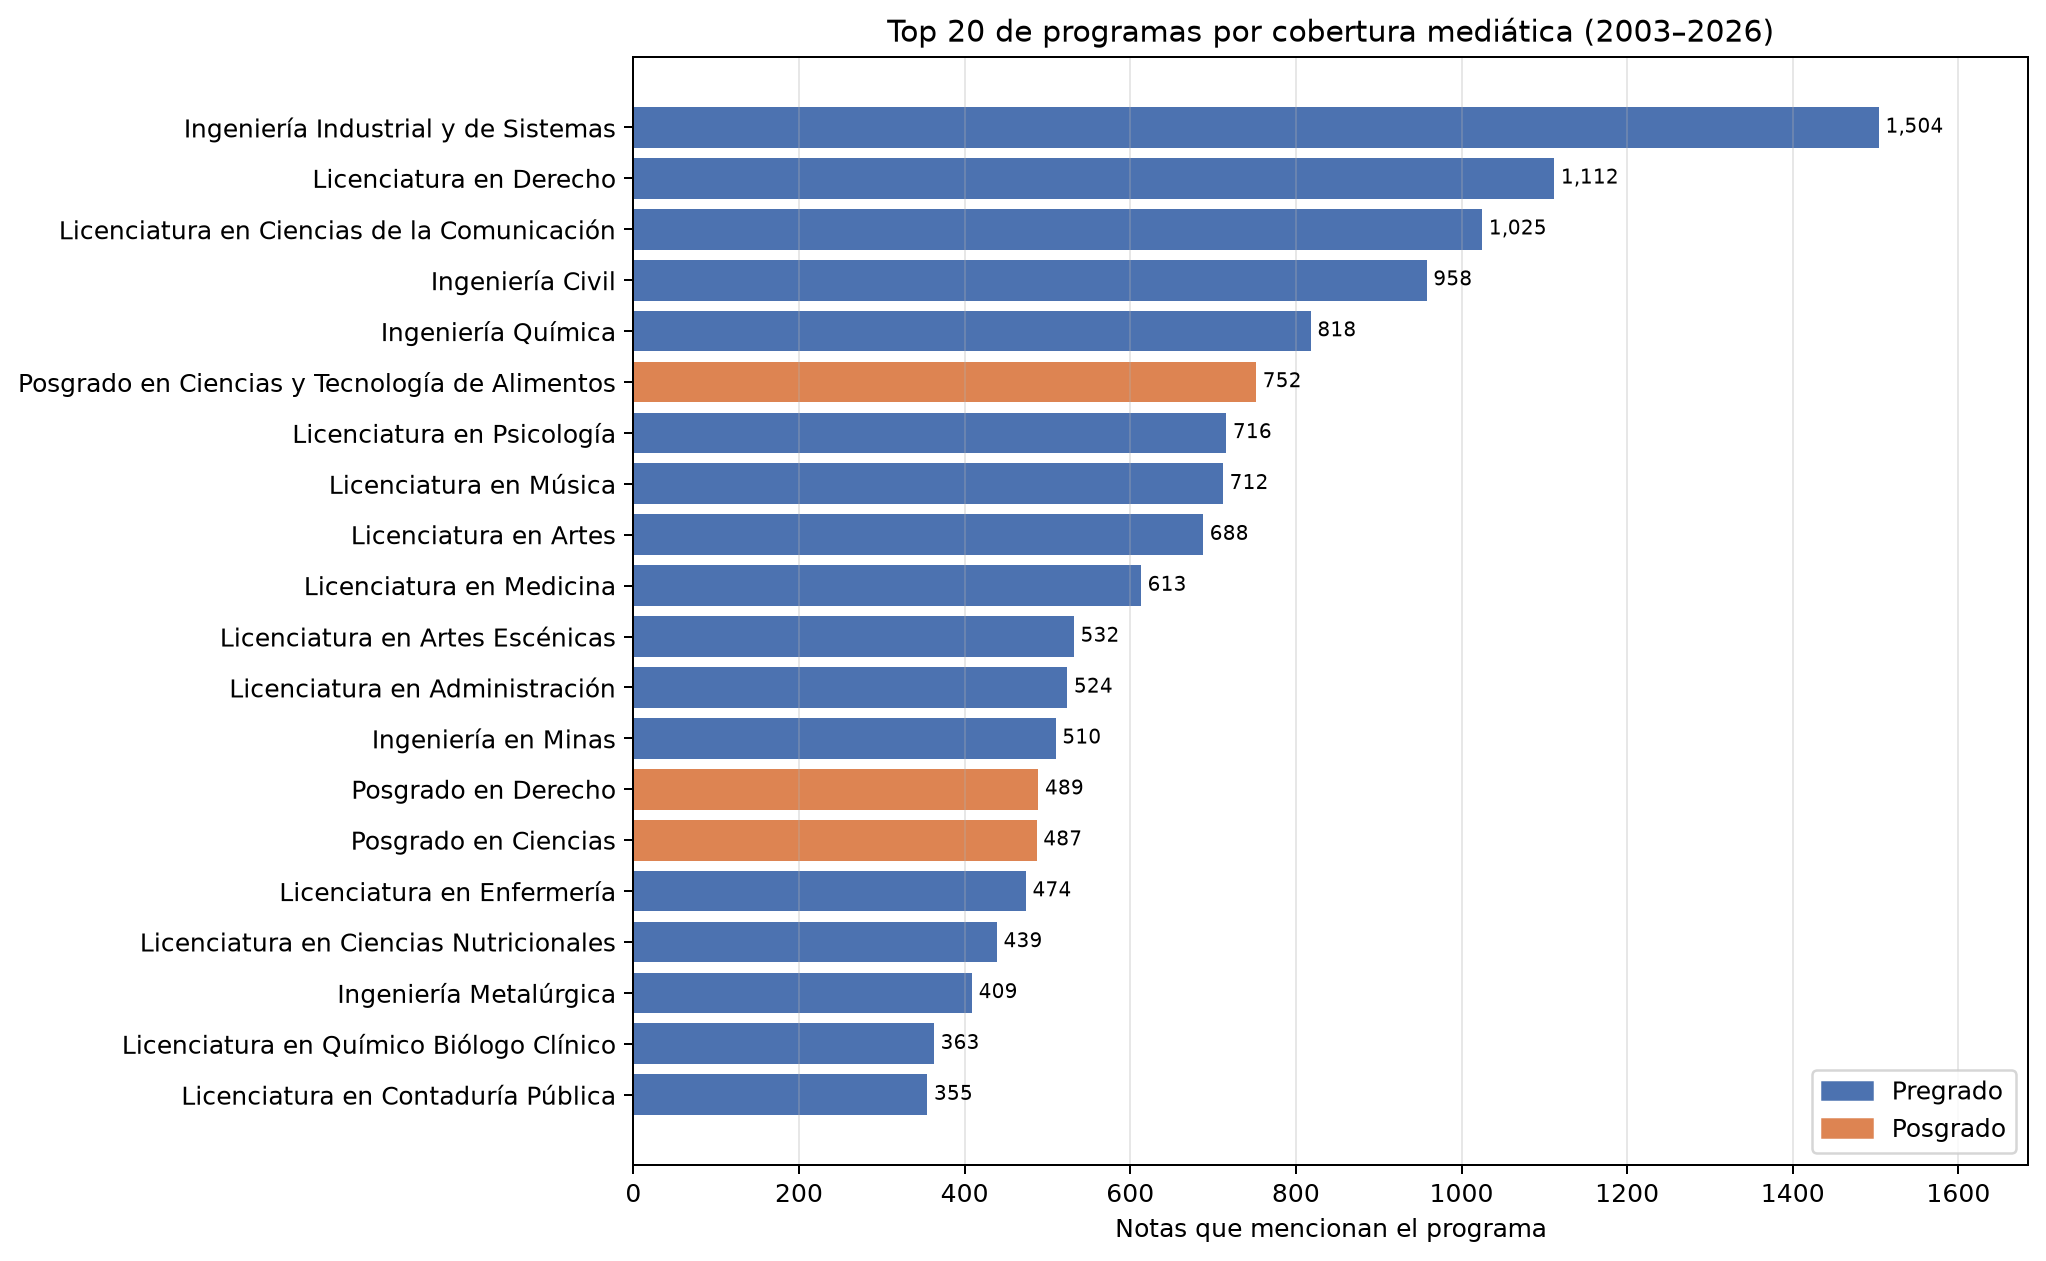

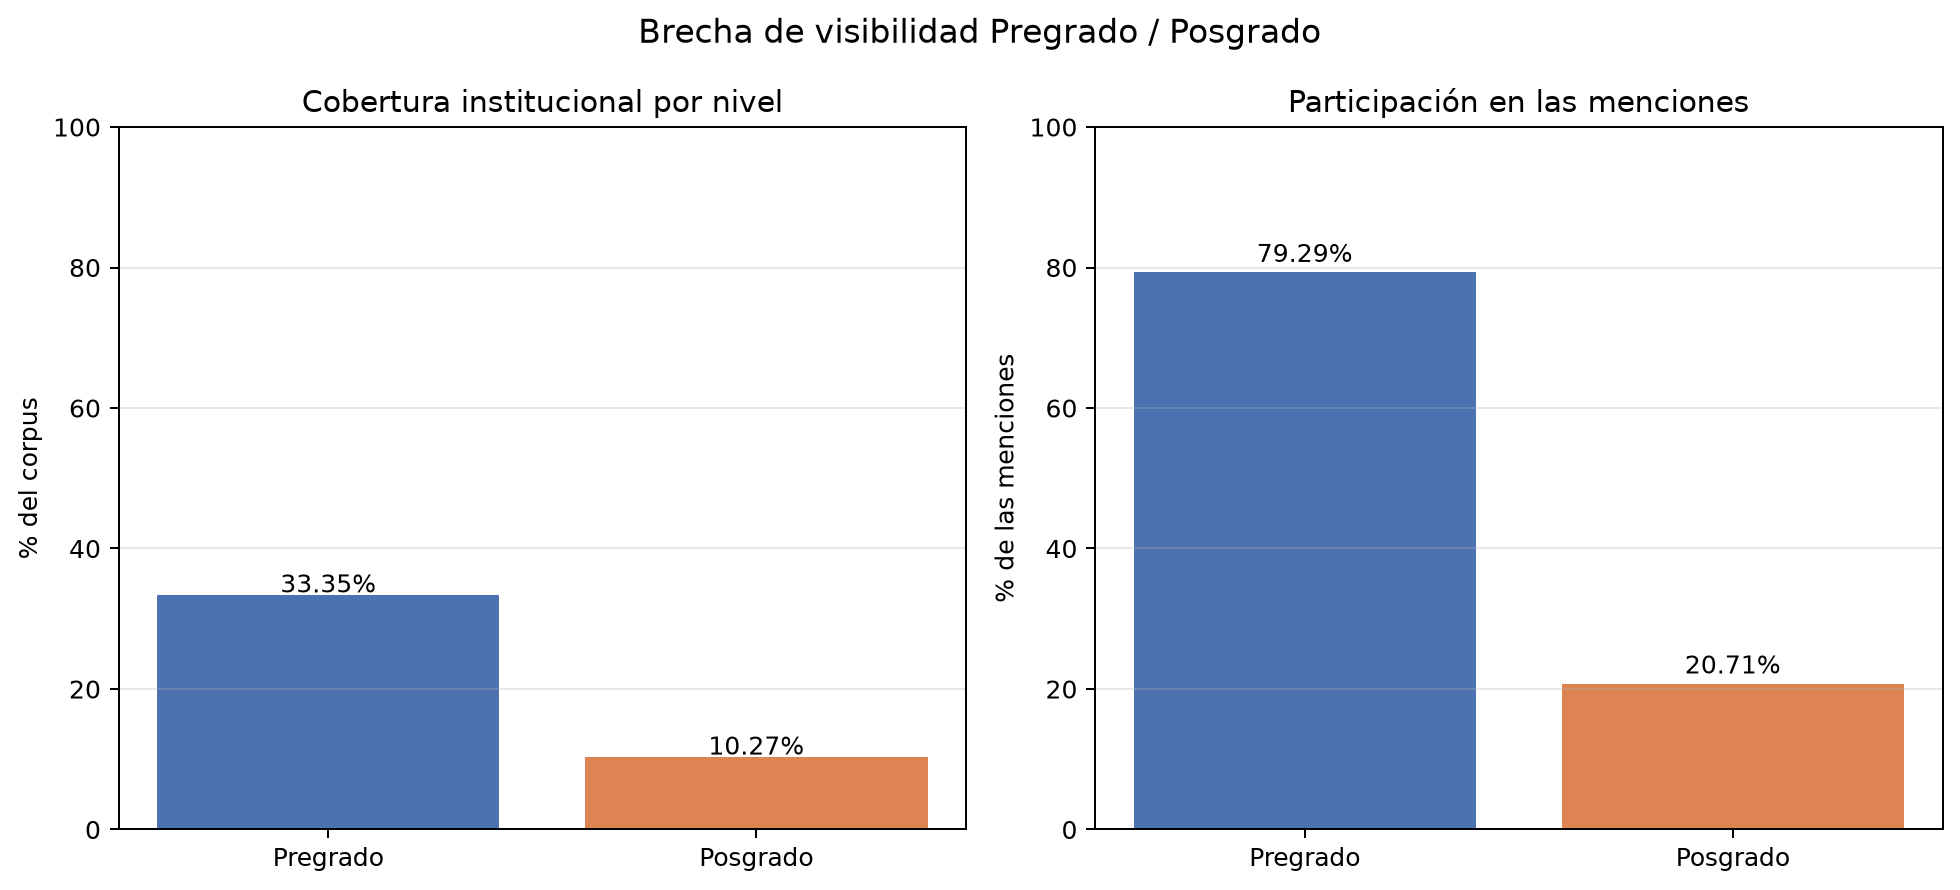

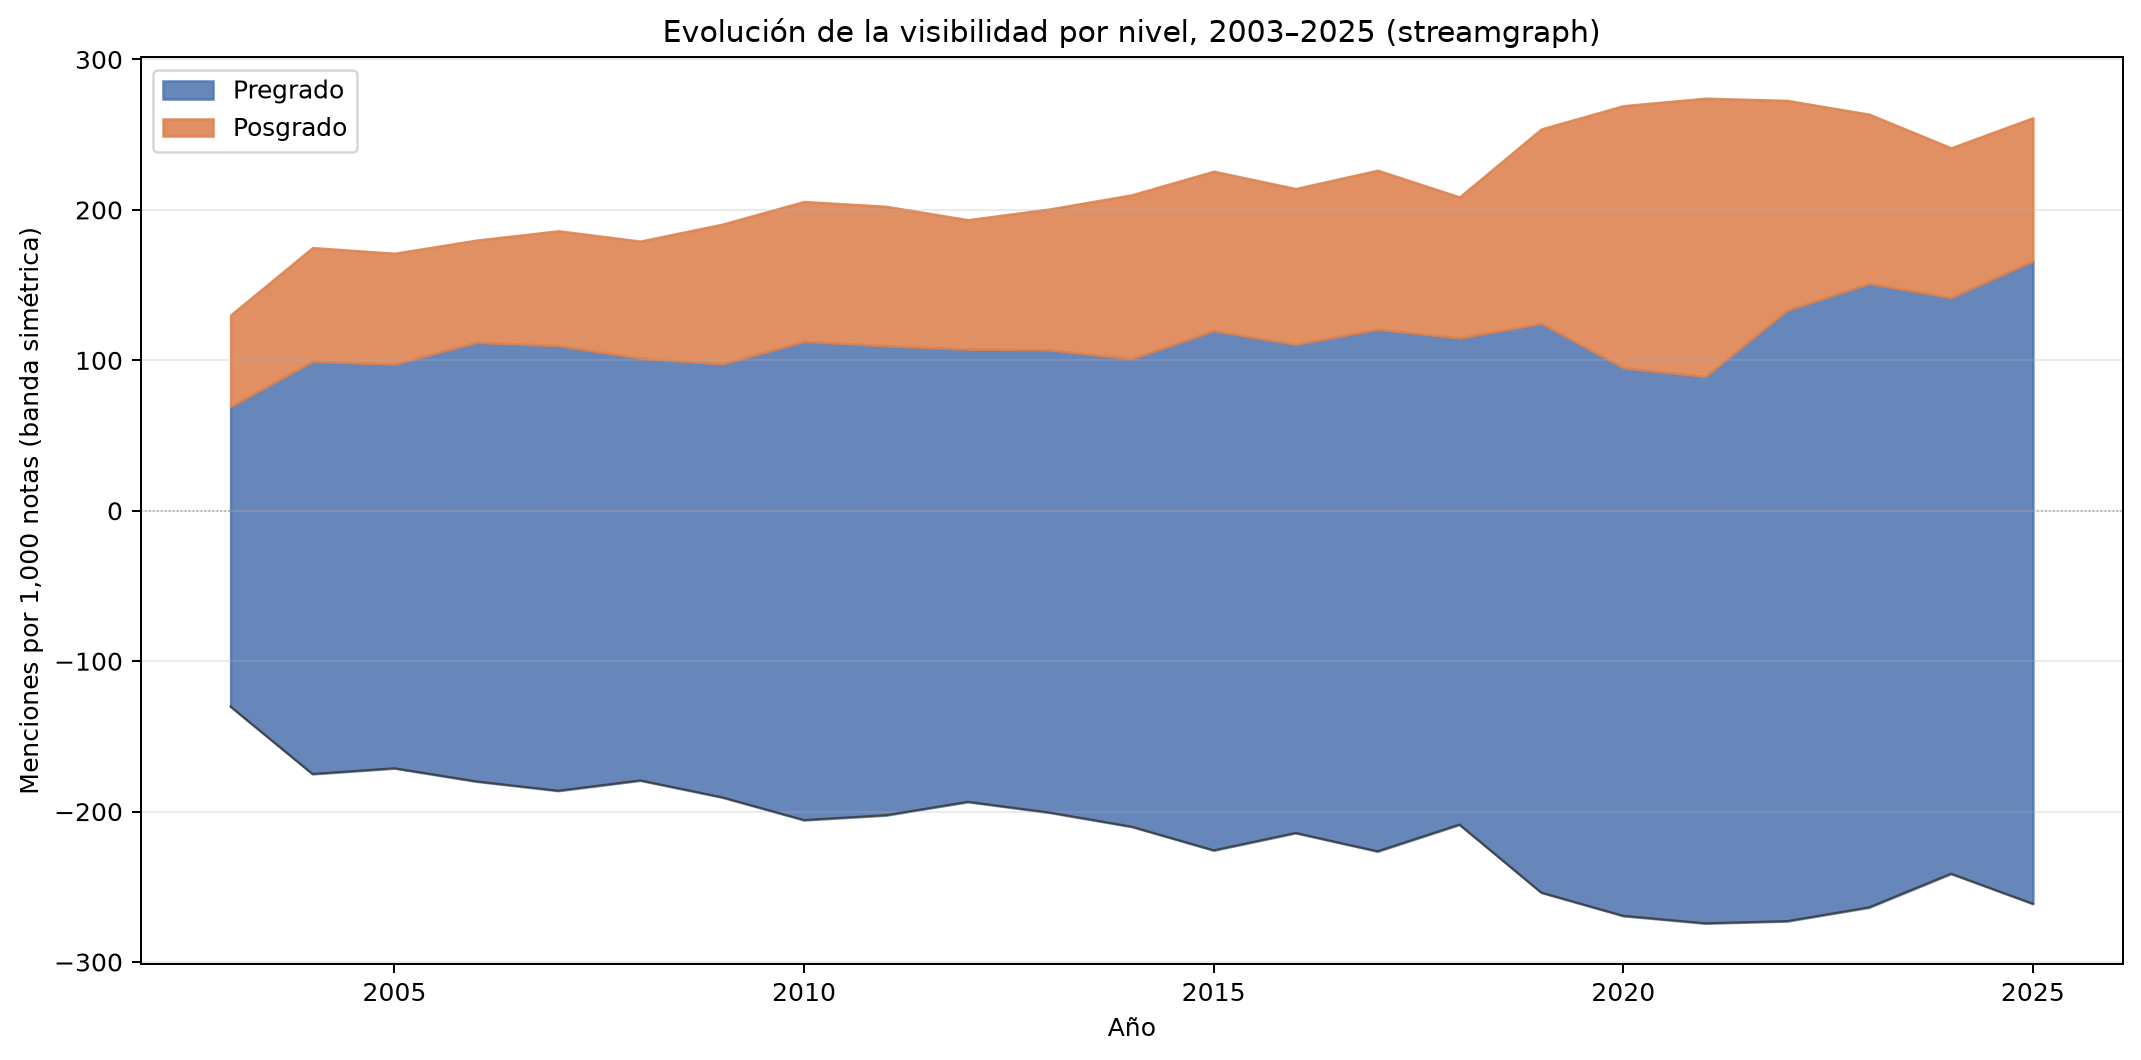

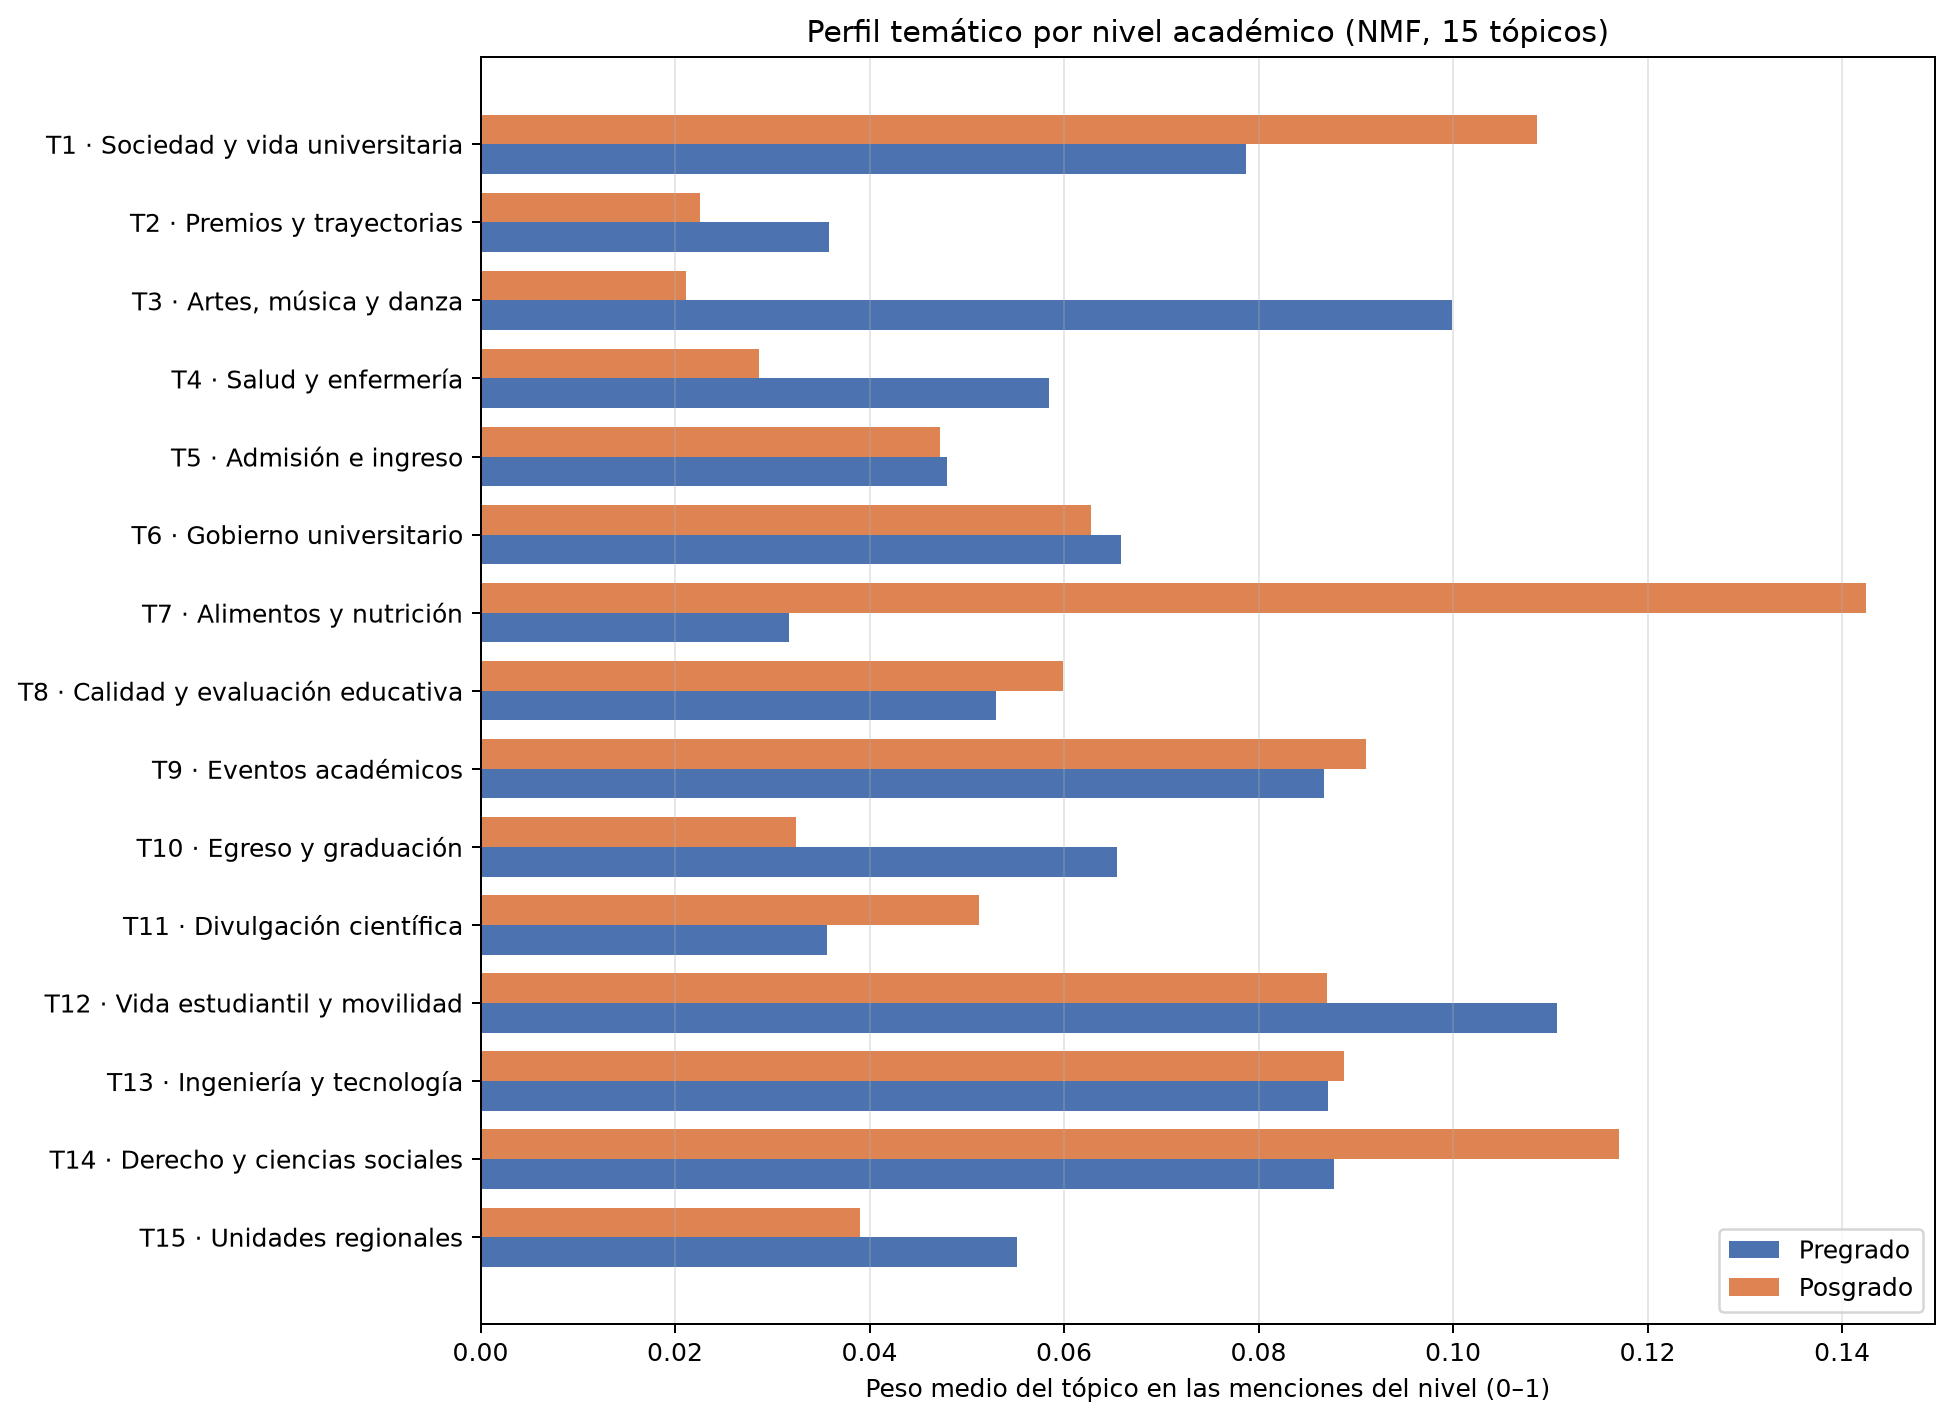

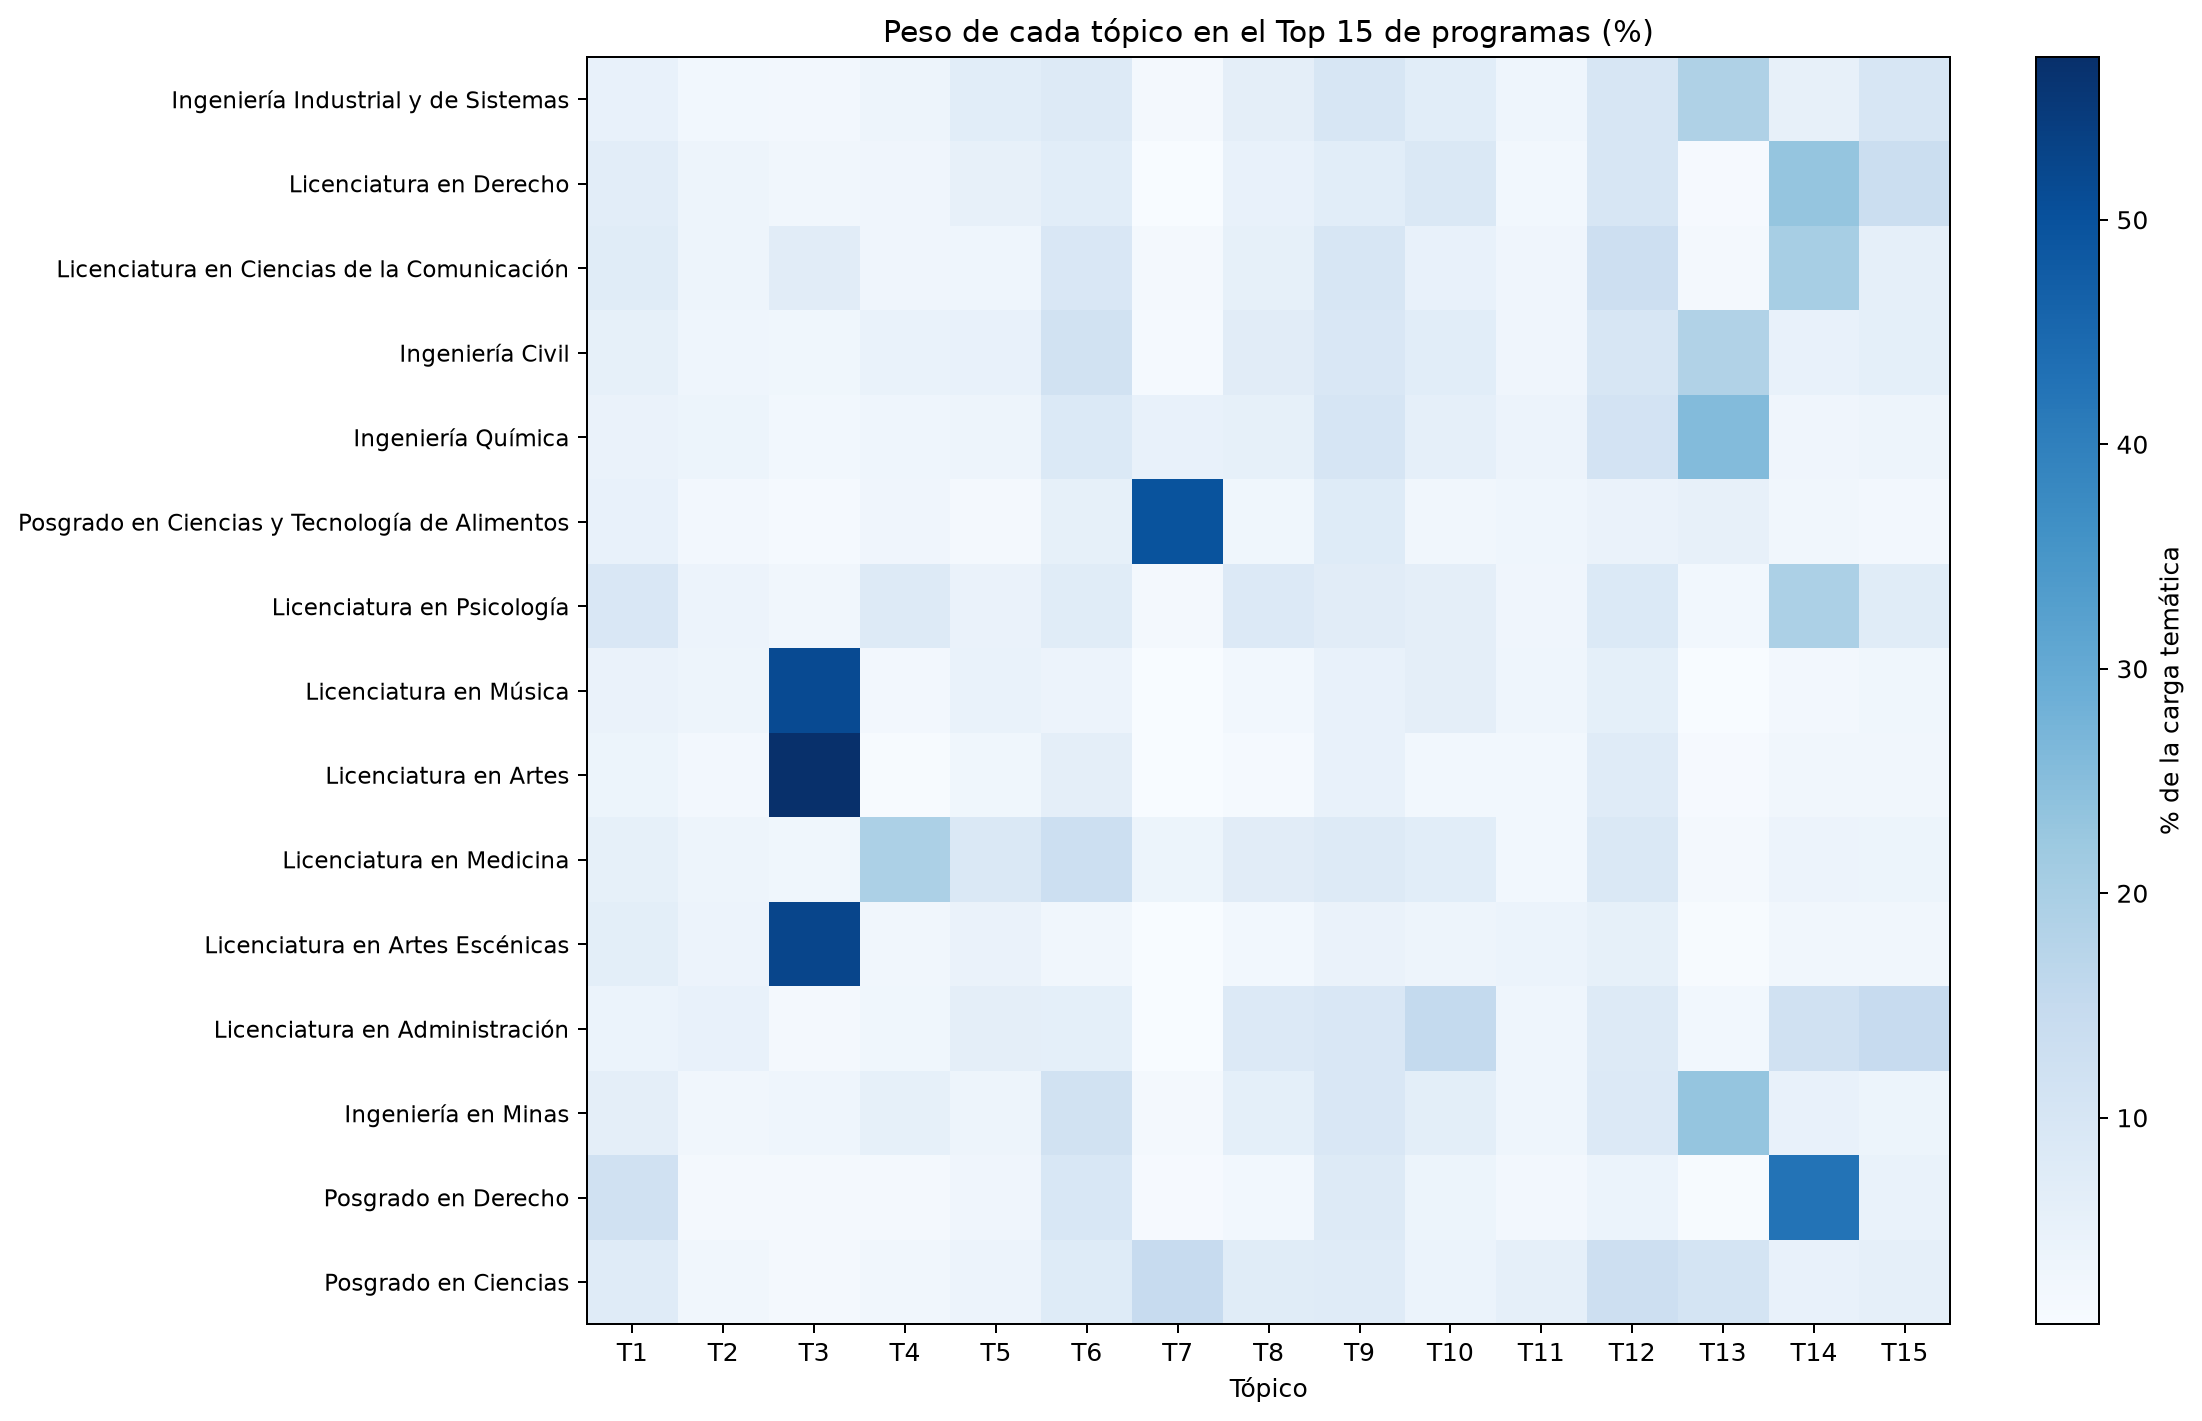

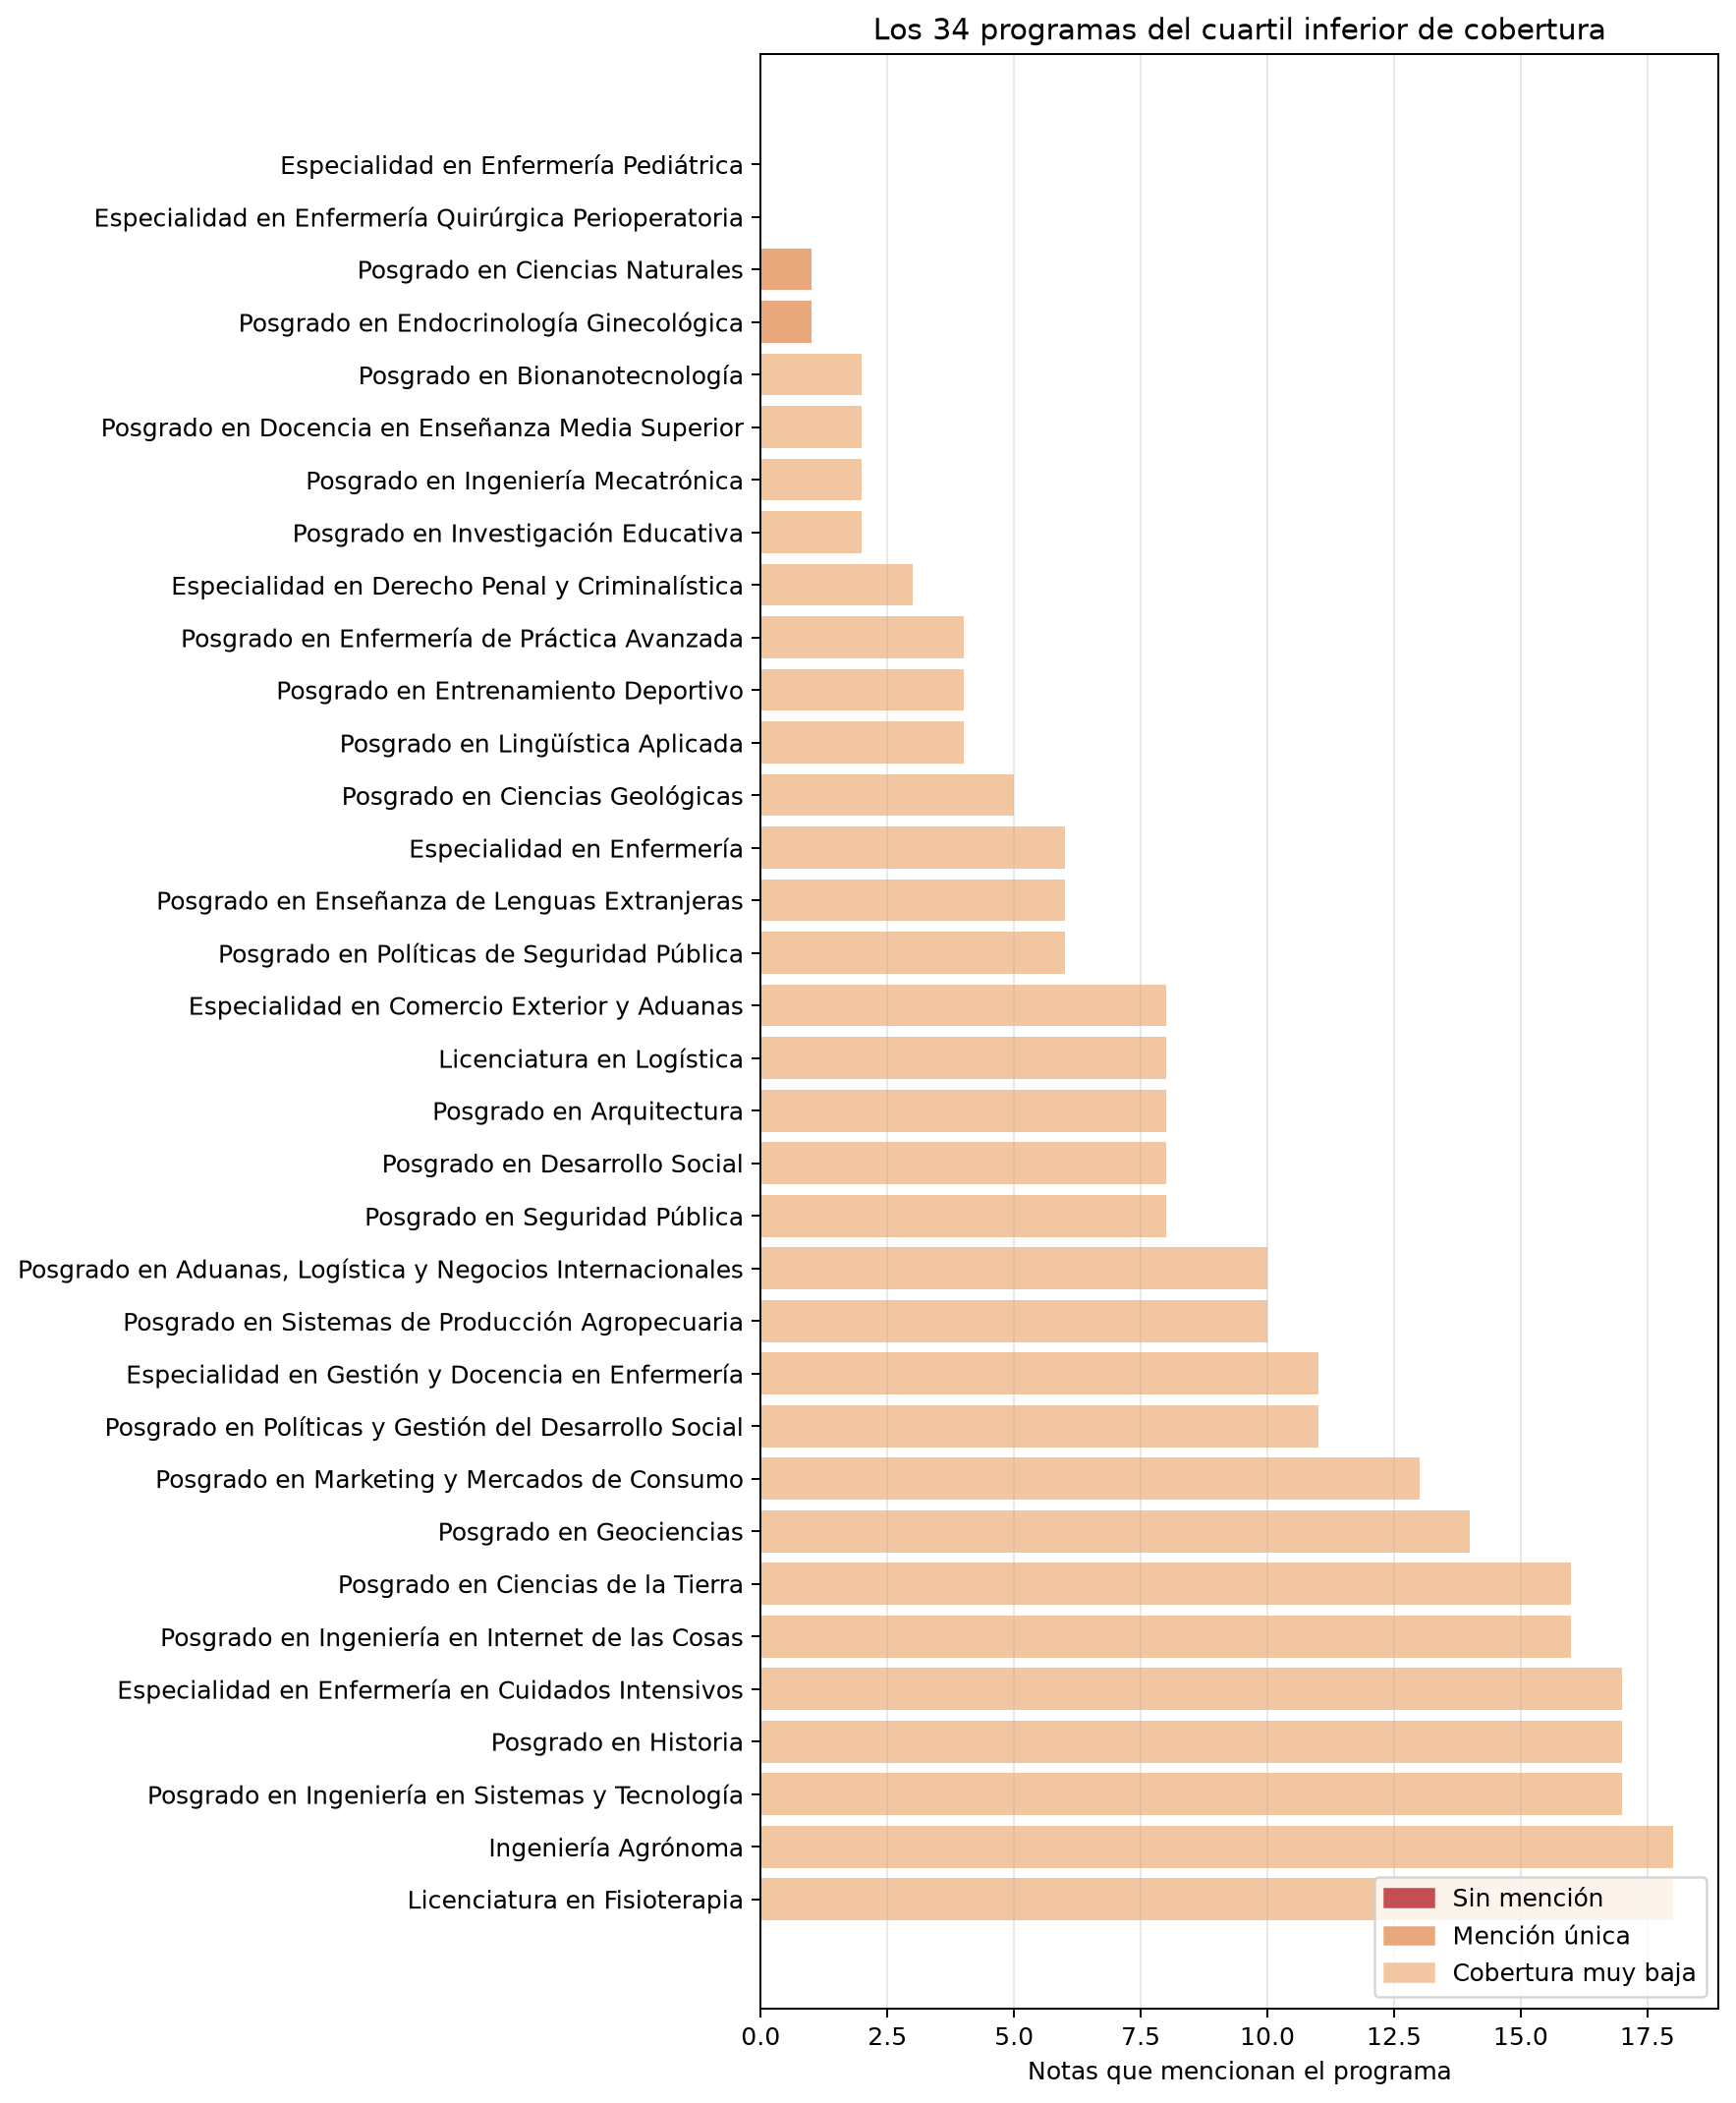

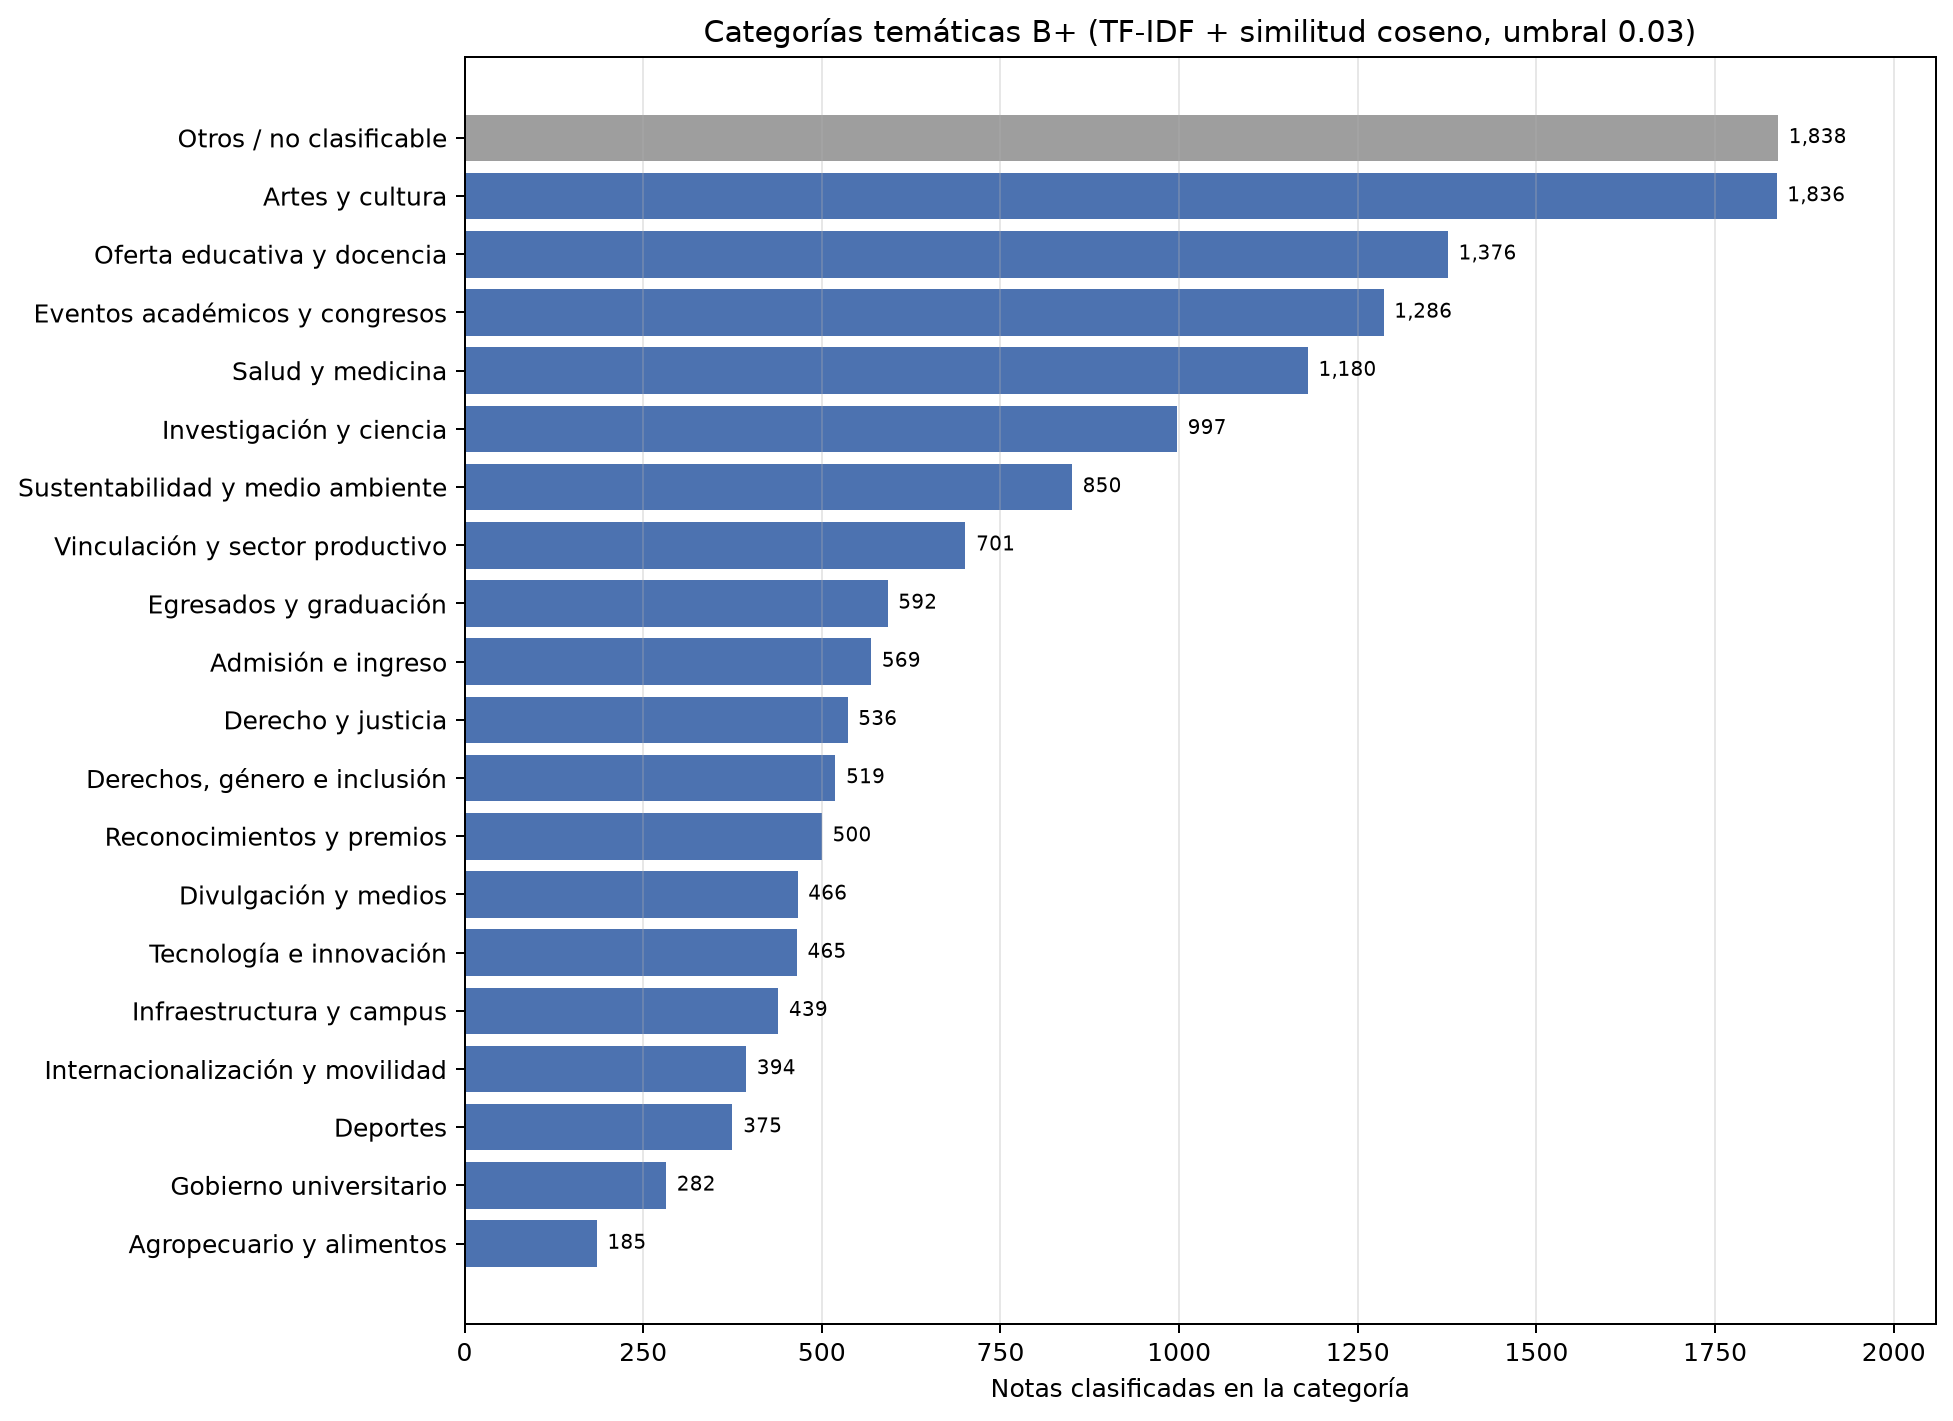

In [15]:
for figura in figuras:
    display(Image(filename=str(figura), width=760))


## 8. Diagnóstico final

La siguiente tabla resume los hallazgos. **No modifica ningún archivo**: es el resultado de
la revisión para que decidas qué corregir antes de la entrega.


In [16]:
diagnostico = pd.DataFrame(hallazgos)
display(diagnostico)

conteo = diagnostico["Estado"].value_counts()
print("\nResumen:")
print(conteo.to_string())
print("\nObservaciones que requieren decisión:")
for fila in diagnostico.loc[diagnostico["Estado"].str.contains("observ", case=False), "Detalle"]:
    print("  -", fila)

print("\nLa libreta no escribió archivos: es una auditoría de solo lectura.")


,Etapa,Estado,Detalle
0,1. Crudo,OK con observaciones,"37,975 filas; 37,975 enlaces únicos; 0 enlaces..."
1,2. Corpus,OK con observación,"37,882 notas internas; 93 filas descartadas; 1..."
2,3. Cuerpos,OK con observación,"37,882 cuerpos; 100% HTTP 200; 10 cuerpos ≤50 ..."
3,4. Menciones,OK,"22,403 menciones en 15,386 notas; 129 programa..."
4,5. Cobertura,OK con observaciones,Totales reconciliados; notas por nivel no son ...
5,6. Tópicos,OK,"15 temas; 1,935 filas (129×15); pesos por prog..."
6,6b. Categorías B+,OK,"20 categorías; 15,386 notas; 1,838 en Otros."
7,7. Narrativa,OK,Reporte y siete figuras presentes; las cifras ...



Resumen:
Estado
OK                      4
OK con observaciones    2
OK con observación      2

Observaciones que requieren decisión:
  - 37,975 filas; 37,975 enlaces únicos; 0 enlaces duplicados extra; 286/288 meses; muestra con 1 enlace fuera del crudo.
  - 37,882 notas internas; 93 filas descartadas; 12 títulos inválidos conservados por cuerpo.
  - 37,882 cuerpos; 100% HTTP 200; 10 cuerpos ≤50 caracteres (fecha + punto).
  - Totales reconciliados; notas por nivel no son aditivas (16,522 vs 15,386); cobertura_anual omite ceros; 2026/2020s/2025-2029 son parciales.

La libreta no escribió archivos: es una auditoría de solo lectura.


### Cómo leer este diagnóstico

- **OK:** el artefacto cumple el contrato de la etapa.
- **OK con observación:** los totales son correctos, pero hay un detalle documentado que
  conviene decidir antes de la entrega (cuerpos vacíos, muestra histórica, ceros ausentes,
  periodos parciales).
- **Fallo:** un `assert` detendría la libreta; si eso ocurre, el pipeline cambió y hay que
  revisar el script que generó el artefacto.

**Siguiente paso sugerido:** usar esta libreta como checklist antes de regenerar el snapshot.
Si una observación requiere cambio de datos, se corrige en el script correspondiente y se
vuelve a ejecutar la etapa; no se edita el Parquet a mano.
